In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
from statsmodels.tsa.seasonal import STL, seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor

df = pd.read_excel('UK_House_Prices.xlsx')
print(df.head)

<bound method NDFrame.head of       Transaction_ID       Date Region        Lead_Name Local_Authority  \
0                  1 2019-06-14  North        Jack Hall      Manchester   
1                  2 2015-03-25  North       Ella Jones      Manchester   
2                  3 2017-07-23  North  Olivia Williams      Manchester   
3                  4 2022-03-08  North     Grace Wilson      Manchester   
4                  5 2021-12-24  North     Olivia Patel      Manchester   
...              ...        ...    ...              ...             ...   
1495            1496 2015-06-20  South     Emily Wright      Chelmsford   
1496            1497 2021-07-09  South     Arthur Green      Chelmsford   
1497            1498 2020-04-19  South     Sophia Jones      Chelmsford   
1498            1499 2017-08-27  South      Oscar Brown      Chelmsford   
1499            1500 2023-08-02  South      Isla Taylor      Chelmsford   

      Property_Type     Tenure  Price_GBP  Floor_Area_m2  Number_of_B

In [2]:
print("Variable information:")
print(df.info())

Variable information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   Transaction_ID                 1500 non-null   int64         
 1   Date                           1500 non-null   datetime64[ns]
 2   Region                         1500 non-null   object        
 3   Lead_Name                      1500 non-null   object        
 4   Local_Authority                1500 non-null   object        
 5   Property_Type                  1500 non-null   object        
 6   Tenure                         1500 non-null   object        
 7   Price_GBP                      1484 non-null   float64       
 8   Floor_Area_m2                  1489 non-null   float64       
 9   Number_of_Bedrooms             1487 non-null   float64       
 10  IMD_Decile                     1490 non-null   float64       


In [3]:
print("Missing values per column:")
print(df.isna().sum()) #not too many missing values that it would be harmful to remove, therefore we will remove any column with missing values as invalid entries. 


Missing values per column:
Transaction_ID                    0
Date                              0
Region                            0
Lead_Name                         0
Local_Authority                   0
Property_Type                     0
Tenure                            0
Price_GBP                        16
Floor_Area_m2                    11
Number_of_Bedrooms               13
IMD_Decile                       10
Average_Mortgage_Rate_Percent    10
dtype: int64


In [4]:
#not too many missing values that it would be harmful to remove, therefore we will remove any column with missing values as invalid entries.
df_NoEmpty = df.dropna()
print(df_NoEmpty.shape)  # see how many rows remain

(1440, 12)


In [5]:
#see  60 data entries have been removed, drop in the ocean for 1500 starting entries. 
#remove lead name for privacy protection, we have trans ID to track entries.
df1 = df_NoEmpty.drop(columns=['Lead_Name'])
#we will now have a look at our outliers and contextually remove and replace them.
#no houses can have less than 1 bedroom, or negative values that should be positive, these will be deleted (deemed not a house.)
#asked generative AI to provide code for outliers and only tweaked variable names.
Q1 = df1['Price_GBP'].quantile(0.25)
Q3 = df1['Price_GBP'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df1[(df1['Price_GBP'] < lower_bound) | (df1['Price_GBP'] > upper_bound)]
mean = df1['Price_GBP'].mean()
print(outliers)
print('Q3 =',Q3)
print('Q1 =',Q1)
print('IQR = ', IQR)
print('mean house price =', mean)


      Transaction_ID       Date Region Local_Authority  Property_Type  \
269              270 2019-07-24  North       Sheffield           Flat   
508              509 2020-05-20  North            Hull       Detached   
517              518 2016-07-28  North            Hull           Flat   
660              661 2023-11-24  North       Blackpool       Terraced   
1319            1320 2022-03-21  South          Woking       Terraced   
1320            1321 2020-08-19  South          Woking  Semi-Detached   
1351            1352 2019-10-18  South      Canterbury       Detached   
1405            1406 2016-06-17  South      Canterbury       Terraced   

         Tenure   Price_GBP  Floor_Area_m2  Number_of_Bedrooms  IMD_Decile  \
269   Leasehold   4186460.0           45.0                 1.0         4.0   
508    Freehold   6165778.0         1104.0                14.0         5.0   
517   Leasehold   4233117.0           66.0                 2.0         5.0   
660    Freehold  11481752.0   

In [6]:
#obvious typos should be replaced: only have 8 outliers so we can observe each one, outlying vals are not always incorrect.
#row 269, delete, typo not obvious, value not realistic
#row 508, keep, understandable outlier, stays as it makes sense logically, massive house, massive price 
#row 517, delete, 4m for a small 2 bed, nah
#row 660, keep, massive house, massive price tag, seems plausible, stays.
#row 1319, delete, small, 2 bed, 4m, unrealistic
#row 1320, delete, small, too expensive. 
#row 1351, keep, large floor space, 8 beds, unlikely but not impossible
#row 1405, delete, doesnt make sense, small 3bed. 
df2 = df1.drop([269, 517, 1319, 1320, 1405])
print(df2.shape)   #check our code has done the correct thing.



#no houses can have less than 1 bedroom, or negative values that should be positive, these will be deleted (deemed not a house.)
#notice that IQR > Q1 val therefore, negative house prices are technically not outliers, thats gotta be fixed.
#we say any house selling for less than 30k is a mistake to fix this. 
df3 = df2[df2['Price_GBP'] > 30000]
df4 = df3[df3['Floor_Area_m2'] > 10]
df5 = df4[df4['Number_of_Bedrooms'] > 0]
print(df5.shape)
print("Variable information:")
print(df5.info())


(1435, 11)
(1402, 11)
Variable information:
<class 'pandas.core.frame.DataFrame'>
Index: 1402 entries, 0 to 1499
Data columns (total 11 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   Transaction_ID                 1402 non-null   int64         
 1   Date                           1402 non-null   datetime64[ns]
 2   Region                         1402 non-null   object        
 3   Local_Authority                1402 non-null   object        
 4   Property_Type                  1402 non-null   object        
 5   Tenure                         1402 non-null   object        
 6   Price_GBP                      1402 non-null   float64       
 7   Floor_Area_m2                  1402 non-null   float64       
 8   Number_of_Bedrooms             1402 non-null   float64       
 9   IMD_Decile                     1402 non-null   float64       
 10  Average_Mortgage_Rate_Percent  1402 non-null 

In [7]:
#outliers now with cleaner dataset. 
Q1 = df5['Price_GBP'].quantile(0.25)
Q3 = df5['Price_GBP'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df5[(df5['Price_GBP'] < lower_bound) | (df5['Price_GBP'] > upper_bound)]
mean = df5['Price_GBP'].mean()
print(outliers)
print('Q3 =',Q3)
print('Q1 =',Q1)
print('IQR = ', IQR)
print('mean house price =', mean)

      Transaction_ID       Date Region Local_Authority Property_Type  \
508              509 2020-05-20  North            Hull      Detached   
660              661 2023-11-24  North       Blackpool      Terraced   
1351            1352 2019-10-18  South      Canterbury      Detached   

        Tenure   Price_GBP  Floor_Area_m2  Number_of_Bedrooms  IMD_Decile  \
508   Freehold   6165778.0         1104.0                14.0         5.0   
660   Freehold  11481752.0          930.0                12.0         1.0   
1351  Freehold   7075700.0          915.0                 8.0         8.0   

      Average_Mortgage_Rate_Percent  
508                            1.98  
660                            5.09  
1351                           1.86  
Q3 = 475692.0
Q1 = 197889.75
IQR =  277802.25
mean house price = 358956.84593437944


In [8]:
#although we previously said these are possibly not incorrect pieces of data, they are still too problematic to include in any model
df6 = df5.drop([508, 660, 1351]) 

In [9]:
#house prices are clean, now we remove the extreme outliers from the rest of our 'float 64 varirables.' 
Q1_area = df6['Floor_Area_m2'].quantile(0.25)
Q3_area = df6['Floor_Area_m2'].quantile(0.75)
IQR_area = Q3_area - Q1_area
lower_bound_area = Q1_area - 3 * IQR_area
upper_bound_area = Q3_area + 3 * IQR_area
outliers_area = df6[(df6['Floor_Area_m2'] < lower_bound_area) | (df6['Floor_Area_m2'] > upper_bound_area)]
mean_area = df6['Floor_Area_m2'].mean()
print(outliers_area)
print('Q3 =',Q3_area)
print('Q1 =',Q1_area)
print('IQR = ', IQR_area)
print('mean Floor_Area_m2 =', mean_area)
standard_deviation_area = df6['Floor_Area_m2'].std()
print('standard deviation =', standard_deviation_area)

      Transaction_ID       Date Region Local_Authority  Property_Type  \
467              468 2022-12-30  North            Hull           Flat   
477              478 2016-07-02  North            Hull       Detached   
770              771 2022-03-09  South       Cambridge       Detached   
885              886 2017-01-03  South          Oxford           Flat   
1057            1058 2018-07-04  South         Reading  Semi-Detached   
1122            1123 2018-07-28  South         Reading  Semi-Detached   
1423            1424 2016-09-30  South      Canterbury           Flat   
1448            1449 2015-12-25  South      Chelmsford  Semi-Detached   

         Tenure  Price_GBP  Floor_Area_m2  Number_of_Bedrooms  IMD_Decile  \
467   Leasehold   287343.0          679.0                 9.0         5.0   
477    Freehold   182166.0          707.0                 7.0         6.0   
770    Freehold   430127.0          615.0                 7.0         5.0   
885   Leasehold   510164.0        

In [10]:
df7 = df6.drop([467, 477, 770, 885, 1057, 1122, 1423, 1448])
Q1_bedrooms = df7['Number_of_Bedrooms'].quantile(0.25)
Q3_bedrooms = df7['Number_of_Bedrooms'].quantile(0.75)
IQR_bedrooms = Q3_bedrooms - Q1_bedrooms
lower_bound_bedrooms = Q1_bedrooms - 3 * IQR_bedrooms
upper_bound_bedrooms = Q3_bedrooms + 3 * IQR_bedrooms
outliers_bedrooms = df7[(df7['Number_of_Bedrooms'] < lower_bound_bedrooms) | (df7['Number_of_Bedrooms'] > upper_bound_bedrooms)]
mean_bedrooms = df6['Number_of_Bedrooms'].mean()
print(outliers_bedrooms)
print('Q3 =',Q3_bedrooms)
print('Q1 =',Q1_bedrooms)
print('IQR = ', IQR_bedrooms)
print('mean Floor_Area_m2 =', mean_bedrooms)
standard_deviation_area = df7['Number_of_Bedrooms'].std()
print('standard deviation =', standard_deviation_area)

      Transaction_ID       Date Region Local_Authority Property_Type  \
566              567 2015-03-03  North          Bolton          Flat   
618              619 2021-12-14  North       Blackpool          Flat   
1372            1373 2017-05-03  South      Canterbury          Flat   

         Tenure  Price_GBP  Floor_Area_m2  Number_of_Bedrooms  IMD_Decile  \
566   Leasehold   241327.0           56.0                15.0         3.0   
618   Leasehold   189734.0           75.0                15.0         3.0   
1372  Leasehold   471207.0           91.0                15.0         6.0   

      Average_Mortgage_Rate_Percent  
566                            2.75  
618                            2.04  
1372                           2.28  
Q3 = 3.0
Q1 = 2.0
IQR =  1.0
mean Floor_Area_m2 = 2.7005003573981416
standard deviation = 1.0938675157214253


In [11]:
df8 = df7.drop([566, 618, 1372])

In [12]:
#i think we have clean dataset now, lets have a look.
print(df8.shape)
print("Variable information:")
print(df8.info())

(1388, 11)
Variable information:
<class 'pandas.core.frame.DataFrame'>
Index: 1388 entries, 0 to 1499
Data columns (total 11 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   Transaction_ID                 1388 non-null   int64         
 1   Date                           1388 non-null   datetime64[ns]
 2   Region                         1388 non-null   object        
 3   Local_Authority                1388 non-null   object        
 4   Property_Type                  1388 non-null   object        
 5   Tenure                         1388 non-null   object        
 6   Price_GBP                      1388 non-null   float64       
 7   Floor_Area_m2                  1388 non-null   float64       
 8   Number_of_Bedrooms             1388 non-null   float64       
 9   IMD_Decile                     1388 non-null   float64       
 10  Average_Mortgage_Rate_Percent  1388 non-null   float64  

In [13]:
#all variables have same no. entries, all data types are presented as expected and there are no empty cells. 
df_clean = df8
#start exploratory analysis on 1388 indivual house sales.

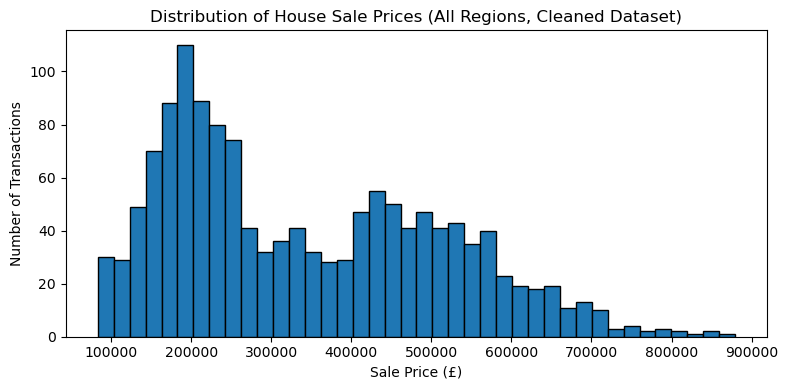

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.hist(df_clean['Price_GBP'], bins=40, edgecolor='black')
plt.title("Distribution of House Sale Prices (All Regions, Cleaned Dataset)")
plt.xlabel("Sale Price (£)")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()     
 #histogram plot code generated by ai

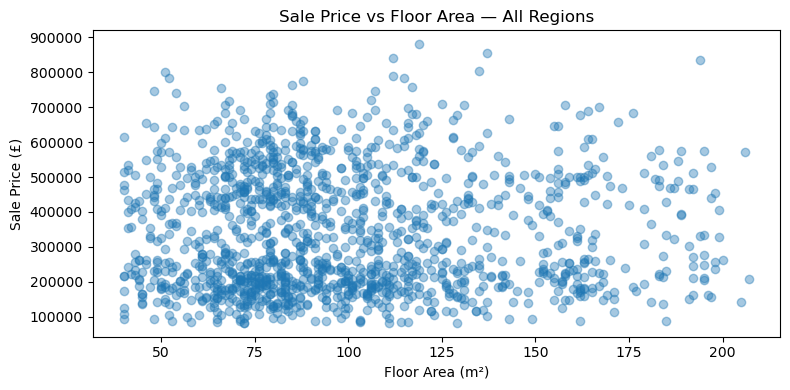

In [15]:
#df looks sensible, house prices tend to be positively skewed.
plt.figure(figsize=(8, 4))
plt.scatter(df_clean['Floor_Area_m2'], df_clean['Price_GBP'], alpha=0.4)
plt.xlabel("Floor Area (m²)")
plt.ylabel("Sale Price (£)")
plt.title("Sale Price vs Floor Area — All Regions")
plt.tight_layout()
plt.show()

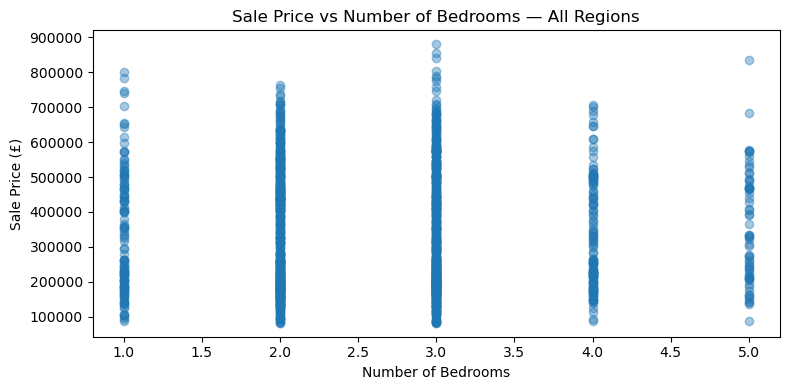

In [16]:
plt.figure(figsize=(8, 4))
plt.scatter(df_clean['Number_of_Bedrooms'], df_clean['Price_GBP'], alpha=0.4)
plt.xlabel("Number of Bedrooms")
plt.ylabel("Sale Price (£)")
plt.title("Sale Price vs Number of Bedrooms — All Regions")
plt.tight_layout()
plt.show()

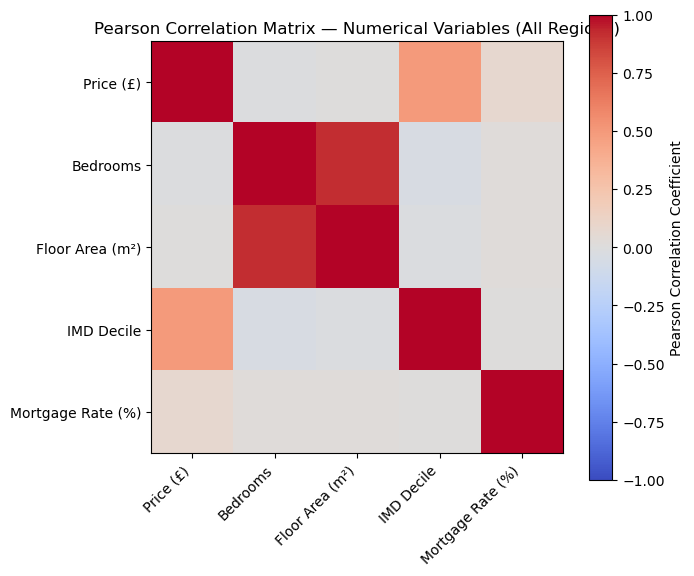

In [17]:
#all whole numbers, therefore no bad data, however this plot doesnt tell us much
import matplotlib.pyplot as plt

corr = df_clean[['Price_GBP', 'Number_of_Bedrooms', 
                 'Floor_Area_m2', 'IMD_Decile', 
                 'Average_Mortgage_Rate_Percent']].corr()

plt.figure(figsize=(7, 6))
plt.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
plt.colorbar(label='Pearson Correlation Coefficient')
plt.xticks(range(len(corr.columns)), ['Price (£)', 'Bedrooms', 'Floor Area (m²)', 'IMD Decile', 'Mortgage Rate (%)'], rotation=45, ha='right')
plt.yticks(range(len(corr.columns)), ['Price (£)', 'Bedrooms', 'Floor Area (m²)', 'IMD Decile', 'Mortgage Rate (%)'])
plt.title("Pearson Correlation Matrix — Numerical Variables (All Regions)")
plt.tight_layout()
plt.show()
#code for corr matrix generated by ai.

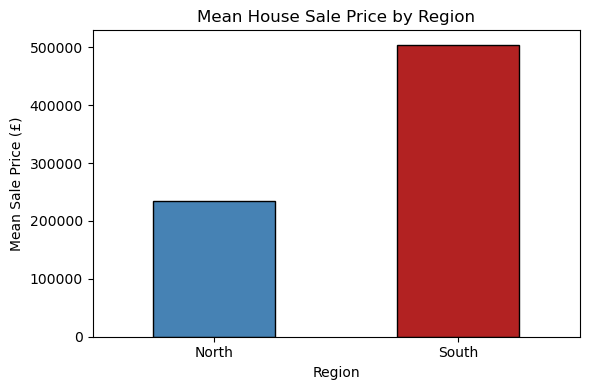

In [18]:
avg_price = df.groupby('Region')['Price_GBP'].mean()

plt.figure(figsize=(6, 4))
avg_price.plot(kind='bar', color=['steelblue', 'firebrick'], edgecolor='black')
plt.title("Mean House Sale Price by Region")
plt.xlabel("Region")
plt.ylabel("Mean Sale Price (£)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [19]:
#we can see a massive difference in the average house value in the south vs in the east.
#we will model these seperately from now on if plausible (must have similar sample sizes and have different means confirmed by t-test)
df_north = df_clean[df_clean['Region'] == 'North']
df_south = df_clean[df_clean['Region'] == 'South']
print("Southern region (rows, column):")
print(df_south.shape)
print("Southern region variable information:")
print(df_south.info())
print("northern region (rows, column):")
print(df_north.shape)
print("northern region variable information:")
print(df_north.info())


Southern region (rows, column):
(691, 11)
Southern region variable information:
<class 'pandas.core.frame.DataFrame'>
Index: 691 entries, 750 to 1499
Data columns (total 11 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   Transaction_ID                 691 non-null    int64         
 1   Date                           691 non-null    datetime64[ns]
 2   Region                         691 non-null    object        
 3   Local_Authority                691 non-null    object        
 4   Property_Type                  691 non-null    object        
 5   Tenure                         691 non-null    object        
 6   Price_GBP                      691 non-null    float64       
 7   Floor_Area_m2                  691 non-null    float64       
 8   Number_of_Bedrooms             691 non-null    float64       
 9   IMD_Decile                     691 non-null    float64       
 10  Average_

In [20]:
#t-test to check if the means are actually different 
t_stat, pval = stats.ttest_ind(df_north["Price_GBP"], df_south["Price_GBP"])
print("p =", pval)

p = 0.0


In [21]:
#p < 0.05, we reject H0 which state the means are the same, we will use these as 2 different data sets now. 
#reclean outliers
Q1_north = df_north['Price_GBP'].quantile(0.25)
Q3_north = df_north['Price_GBP'].quantile(0.75)
IQR_north = Q3_north - Q1_north

lower_bound_north = Q1_north - 1.5 * IQR_north
upper_bound_north = Q3_north + 1.5 * IQR_north

outliers_north = df_north[(df_north['Price_GBP'] < lower_bound_north) | (df_north['Price_GBP'] > upper_bound_north)]
mean = df_north['Price_GBP'].mean()
print(outliers_north)
print('Q3 =',Q3_north)
print('Q1 =',Q1_north)
print('IQR = ', IQR_north)
print('Price_GBP in north mean =', mean)

     Transaction_ID       Date Region Local_Authority  Property_Type  \
56               57 2021-11-27  North      Manchester       Terraced   
75               76 2023-11-12  North       Liverpool       Terraced   
149             150 2021-07-24  North       Liverpool       Terraced   
391             392 2022-11-01  North        Bradford  Semi-Detached   
401             402 2023-11-13  North        Bradford           Flat   
449             450 2021-07-15  North        Bradford           Flat   

        Tenure  Price_GBP  Floor_Area_m2  Number_of_Bedrooms  IMD_Decile  \
56    Freehold   408990.0           67.0                 2.0         4.0   
75    Freehold   381051.0           93.0                 3.0         1.0   
149   Freehold   360170.0           78.0                 2.0         5.0   
391   Freehold   357082.0           86.0                 2.0         4.0   
401  Leasehold   365589.0           52.0                 1.0         3.0   
449  Leasehold   361056.0           54.

In [22]:
df_north = df_north.drop([56, 75, 149, 391, 401, 418, 449])
Q1_south = df_south['Price_GBP'].quantile(0.25)
Q3_south = df_south['Price_GBP'].quantile(0.75)
IQR_south = Q3_south - Q1_south

lower_bound_south = Q1_south - 1.5 * IQR_south
upper_bound_south = Q3_south + 1.5 * IQR_south

outliers_south = df_south[(df_south['Price_GBP'] < lower_bound_south) | (df_south['Price_GBP'] > upper_bound_south)]
mean = df_south['Price_GBP'].mean()
print(outliers_south)
print('Q3 =',Q3_south)
print('Q1 =',Q1_south)
print('IQR = ', IQR_south)
print('Price_GBP mean in south =', mean)

      Transaction_ID       Date Region    Local_Authority  Property_Type  \
781              782 2023-03-19  South          Cambridge  Semi-Detached   
899              900 2023-11-17  South             Oxford           Flat   
967              968 2017-04-05  South  Brighton and Hove       Detached   
1000            1001 2021-09-29  South          Guildford  Semi-Detached   
1149            1150 2016-08-05  South         Winchester       Detached   
1198            1199 2022-12-13  South         Winchester       Terraced   
1286            1287 2022-04-10  South             Woking       Detached   
1339            1340 2021-03-05  South             Woking       Detached   
1356            1357 2023-04-02  South         Canterbury       Detached   

         Tenure  Price_GBP  Floor_Area_m2  Number_of_Bedrooms  IMD_Decile  \
781    Freehold   879500.0          119.0                 3.0         8.0   
899   Leasehold   801586.0           51.0                 1.0         4.0   
967    F

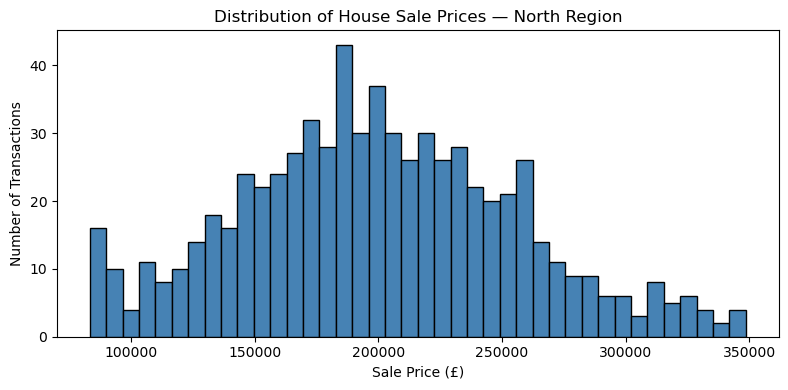

In [23]:
df_south = df_south.drop([781, 899, 967, 1000, 1149, 1286, 1339, 1356])
#replot all graphs with the 2 seperate datasets now to regather shapes of the data.
#check t-test assumptions
plt.figure(figsize=(8, 4))
plt.hist(df_north['Price_GBP'], bins=40, edgecolor='black', color='steelblue')
plt.title("Distribution of House Sale Prices — North Region")
plt.xlabel("Sale Price (£)")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

In [24]:
#northern region still positively skewed however less so now, lets look at south
stat_b, pval_b = stats.shapiro(df_north["Price_GBP"])
print("(North) p=", pval_b)

(North) p= 0.0009238594376272358


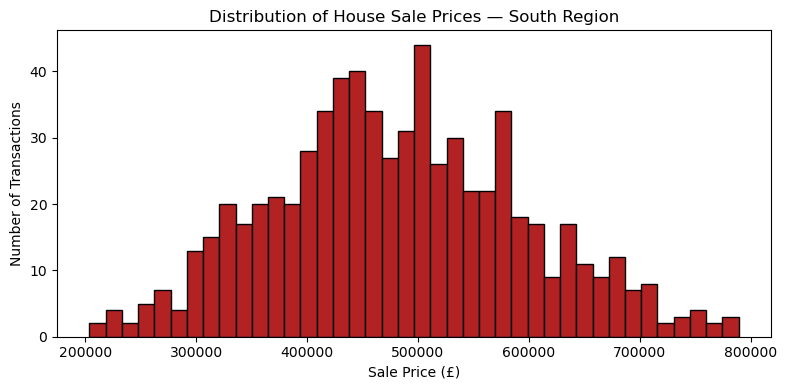

In [25]:
#cannot assume normality from shapiro-wilk test, different test required, t-test not good enough.
plt.figure(figsize=(8, 4))
plt.hist(df_south['Price_GBP'], bins=40, edgecolor='black', color='firebrick')
plt.title("Distribution of House Sale Prices — South Region")
plt.xlabel("Sale Price (£)")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

In [26]:
#looks like normal distribution, lets check 
stat_b, pval_b = stats.shapiro(df_south["Price_GBP"])
print("(south) p=", pval_b)

(south) p= 0.020191722684667547


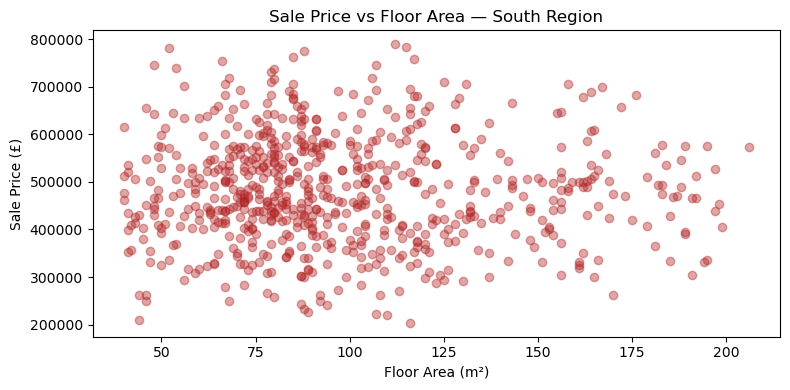

In [27]:
#cannot assume normality for south either as p < 0.05
#central limit theorem states that due to the size of our datasets, this should not matter too much, therefore we still assume difference of means. 
plt.figure(figsize=(8, 4))
plt.scatter(df_south['Floor_Area_m2'], df_south['Price_GBP'], alpha=0.4, color='firebrick')
plt.xlabel("Floor Area (m²)")
plt.ylabel("Sale Price (£)")
plt.title("Sale Price vs Floor Area — South Region")
plt.tight_layout()
plt.show()

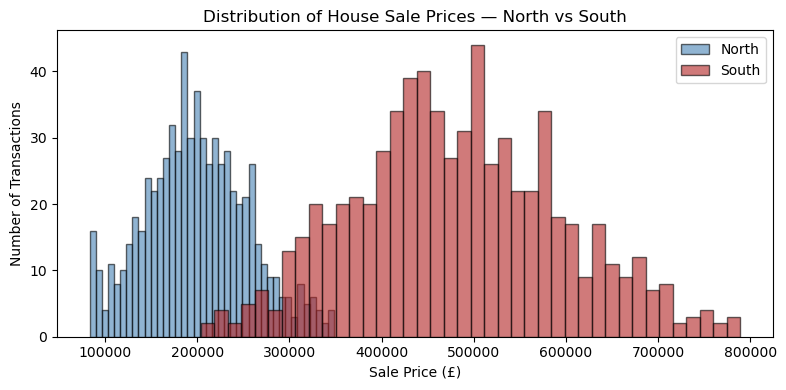

In [28]:
#looks slightly cleaner however still no correlation by the looks of things.
plt.figure(figsize=(8, 4))
plt.hist(df_north["Price_GBP"], label='North', bins=40, alpha=0.6, color='steelblue', edgecolor='black')
plt.hist(df_south["Price_GBP"], label='South', bins=40, alpha=0.6, color='firebrick', edgecolor='black')
plt.xlabel("Sale Price (£)")
plt.ylabel("Number of Transactions")
plt.title("Distribution of House Sale Prices — North vs South")
plt.legend()
plt.tight_layout()
plt.show()

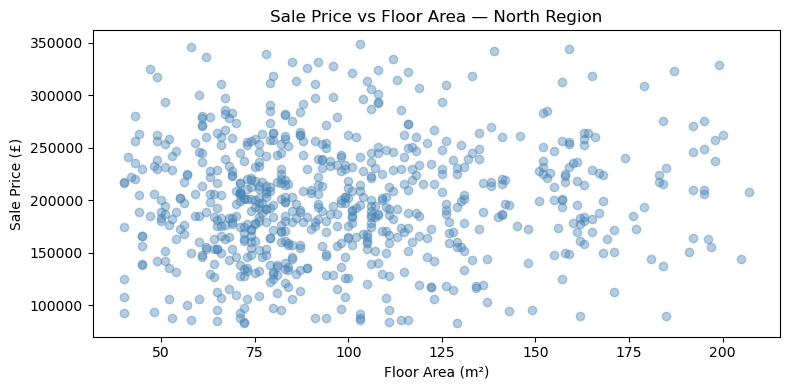

In [29]:
#looks slightly cleaner however still no correlation by the looks of things.
plt.figure(figsize=(8, 4))
plt.scatter(df_north['Floor_Area_m2'], df_north['Price_GBP'], alpha=0.4, color='steelblue')
plt.xlabel("Floor Area (m²)")
plt.ylabel("Sale Price (£)")
plt.title("Sale Price vs Floor Area — North Region")
plt.tight_layout()
plt.show()

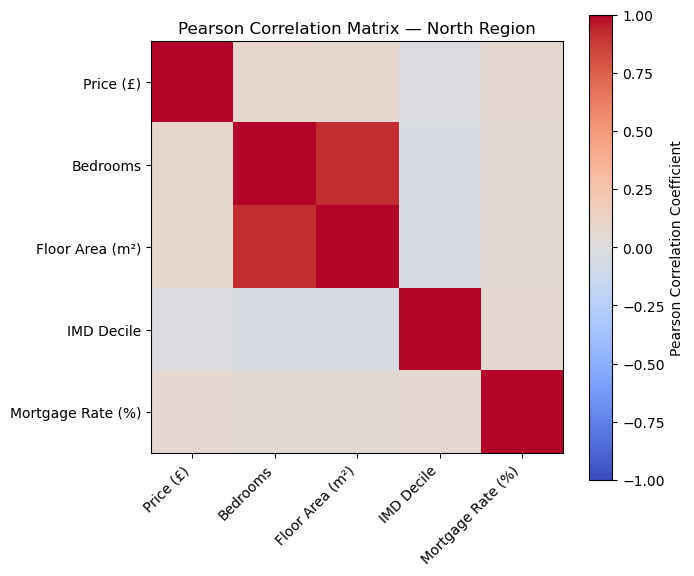

In [30]:
#almost maybe a slight positive correlation? we shall find out
corr = df_north[['Price_GBP', 'Number_of_Bedrooms', 
                 'Floor_Area_m2', 'IMD_Decile', 
                 'Average_Mortgage_Rate_Percent']].corr()

plt.figure(figsize=(7, 6))
plt.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
plt.colorbar(label='Pearson Correlation Coefficient')
plt.xticks(range(len(corr.columns)), ['Price (£)', 'Bedrooms', 'Floor Area (m²)', 'IMD Decile', 'Mortgage Rate (%)'], rotation=45, ha='right')
plt.yticks(range(len(corr.columns)), ['Price (£)', 'Bedrooms', 'Floor Area (m²)', 'IMD Decile', 'Mortgage Rate (%)'])
plt.title("Pearson Correlation Matrix — North Region")
plt.tight_layout()
plt.show()

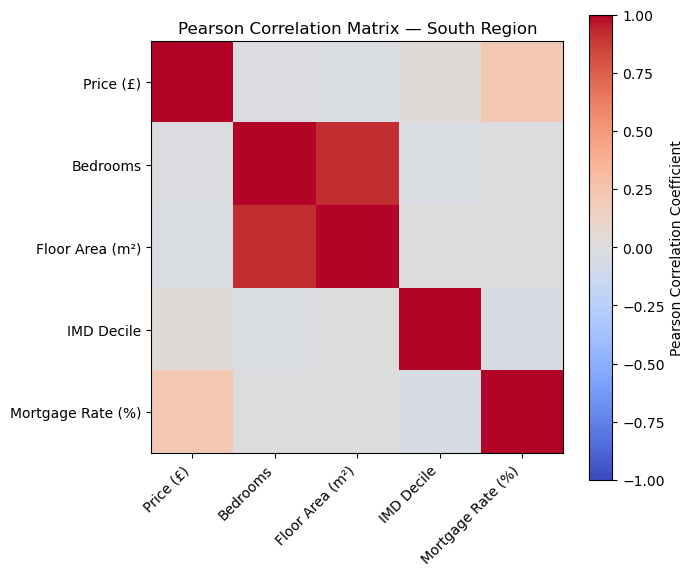

In [31]:
corr = df_south[['Price_GBP', 'Number_of_Bedrooms', 
                 'Floor_Area_m2', 'IMD_Decile', 
                 'Average_Mortgage_Rate_Percent']].corr()

plt.figure(figsize=(7, 6))
plt.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
plt.colorbar(label='Pearson Correlation Coefficient')
plt.xticks(range(len(corr.columns)), ['Price (£)', 'Bedrooms', 'Floor Area (m²)', 'IMD Decile', 'Mortgage Rate (%)'], rotation=45, ha='right')
plt.yticks(range(len(corr.columns)), ['Price (£)', 'Bedrooms', 'Floor Area (m²)', 'IMD Decile', 'Mortgage Rate (%)'])
plt.title("Pearson Correlation Matrix — South Region")
plt.tight_layout()
plt.show()

In [32]:
#nothing seems correlated in either matrix other than floor space and number of bedroom.
#possibly multicolinearity issues if we try to model house price, maybe fix this.
#price and mortgage rate do have a slight correlation in southern region, this is interesting, shall be explored.


In [33]:
print('north data summary:')
print(df_north.describe())
print('south data summary:')
print(df_south.describe())

north data summary:
       Transaction_ID                           Date      Price_GBP  \
count      690.000000                            690     690.000000   
mean       373.217391  2019-06-18 17:54:46.956521728  199767.527536   
min          1.000000            2015-01-01 00:00:00   83271.000000   
25%        187.500000            2017-03-05 18:00:00  161042.250000   
50%        369.500000            2019-07-25 12:00:00  197308.000000   
75%        563.750000            2021-09-02 00:00:00  236480.000000   
max        750.000000            2023-12-29 00:00:00  348603.000000   
std        216.756501                            NaN   55839.325108   

       Floor_Area_m2  Number_of_Bedrooms  IMD_Decile  \
count     690.000000          690.000000  690.000000   
mean       99.408696            2.666667    3.630435   
min        40.000000            1.000000    0.000000   
25%        72.000000            2.000000    2.000000   
50%        92.000000            3.000000    3.000000   
75% 

In [34]:
#shows data was not cleaned properly, imd_decile has max 10, mortgage rate of max 15% (south), and 25%(north) is also fishy.
Q1_north = df_north['IMD_Decile'].quantile(0.25)
Q3_north = df_north['IMD_Decile'].quantile(0.75)
IQR_north = Q3_north - Q1_north

lower_bound_north = Q1_north - 1.5 * IQR_north
upper_bound_north = Q3_north + 1.5 * IQR_north

outliers_north = df_north[(df_north['IMD_Decile'] < lower_bound_north) | (df_north['IMD_Decile'] > upper_bound_north)]
mean = df_north['IMD_Decile'].mean()
print(outliers_north)
print('Q3 =',Q3_north)
print('Q1 =',Q1_north)
print('IQR = ', IQR_north)
print('IMD_Decile mean =', mean)


     Transaction_ID       Date Region Local_Authority  Property_Type  \
266             267 2016-10-12  North       Sheffield  Semi-Detached   
512             513 2018-01-24  North            Hull  Semi-Detached   
727             728 2019-03-10  North   Middlesbrough           Flat   

        Tenure  Price_GBP  Floor_Area_m2  Number_of_Bedrooms  IMD_Decile  \
266   Freehold   224027.0          118.0                 3.0        10.0   
512   Freehold   139468.0          106.0                 3.0        20.0   
727  Leasehold   124992.0           40.0                 1.0        10.0   

     Average_Mortgage_Rate_Percent  
266                           2.35  
512                           1.91  
727                           1.94  
Q3 = 5.0
Q1 = 2.0
IQR =  3.0
IMD_Decile mean = 3.630434782608696


In [35]:
#drop these, do same for south
df_north = df_north.drop([266, 512, 727])
Q1_south = df_south['IMD_Decile'].quantile(0.25)
Q3_south = df_south['IMD_Decile'].quantile(0.75)
IQR_south = Q3_south - Q1_south

lower_bound_south = Q1_south - 1.5 * IQR_south
upper_bound_south = Q3_south + 1.5 * IQR_south

outliers_south = df_south[(df_south['IMD_Decile'] < lower_bound_south) | (df_south['IMD_Decile'] > upper_bound_south)]
mean = df_south['IMD_Decile'].mean()
print(outliers_south)
print('Q3 =',Q3_south)
print('Q1 =',Q1_south)
print('IQR = ', IQR_south)
print('IMD_Decile mean =', mean)

     Transaction_ID       Date Region Local_Authority Property_Type    Tenure  \
987             988 2019-01-05  South       Guildford      Detached  Freehold   

     Price_GBP  Floor_Area_m2  Number_of_Bedrooms  IMD_Decile  \
987   589425.0          135.0                 3.0        20.0   

     Average_Mortgage_Rate_Percent  
987                            2.0  
Q3 = 8.0
Q1 = 5.0
IQR =  3.0
IMD_Decile mean = 6.537335285505124


In [36]:
#drop outlier.
df_south = df_south.drop([987])
#do for mortgage rate.
Q1_south = df_south['Average_Mortgage_Rate_Percent'].quantile(0.25)
Q3_south = df_south['Average_Mortgage_Rate_Percent'].quantile(0.75)
IQR_south = Q3_south - Q1_south

lower_bound_south = Q1_south - 1.5 * IQR_south
upper_bound_south = Q3_south + 1.5 * IQR_south

outliers = df_south[(df_south['Average_Mortgage_Rate_Percent'] < lower_bound_south) | (df_south['Average_Mortgage_Rate_Percent'] > upper_bound_south)]
mean = df_south['Average_Mortgage_Rate_Percent'].mean()
print(outliers)
print('Q3 =',Q3_south)
print('Q1 =',Q1_south)
print('IQR = ', IQR_south)
print('Average_Mortgage_Rate_Percent in south =', mean)

      Transaction_ID       Date Region Local_Authority  Property_Type  \
757              758 2023-11-03  South       Cambridge       Detached   
760              761 2023-01-31  South       Cambridge           Flat   
762              763 2023-12-30  South       Cambridge  Semi-Detached   
766              767 2023-11-11  South       Cambridge       Detached   
769              770 2023-02-13  South       Cambridge       Terraced   
...              ...        ...    ...             ...            ...   
1456            1457 2023-12-17  South      Chelmsford       Detached   
1473            1474 2022-04-17  South      Chelmsford           Flat   
1487            1488 2019-12-29  South      Chelmsford           Flat   
1492            1493 2023-10-05  South      Chelmsford       Terraced   
1499            1500 2023-08-02  South      Chelmsford       Detached   

         Tenure  Price_GBP  Floor_Area_m2  Number_of_Bedrooms  IMD_Decile  \
757    Freehold   423878.0          169.0     

In [37]:
#way too many outliers to get rid of them all (90), the data is clearly telling that this is something that can fluctuate. 
#still do same for north mortgage rates to see if they behave the same 
Q1_north = df_north['Average_Mortgage_Rate_Percent'].quantile(0.25)
Q3_north = df_north['Average_Mortgage_Rate_Percent'].quantile(0.75)
IQR_north = Q3_north - Q1_north

lower_bound_north = Q1_north - 1.5 * IQR_north
upper_bound_north = Q3_north + 1.5 * IQR_north

outliers_north = df_north[(df_north['Average_Mortgage_Rate_Percent'] < lower_bound_north) | (df_north['Average_Mortgage_Rate_Percent'] > upper_bound_north)]
mean = df_north['Average_Mortgage_Rate_Percent'].mean()
print(outliers_north)
print('Q3 =',Q3_north)
print('Q1 =',Q1_north)
print('IQR = ', IQR_north)
print('Average_Mortgage_Rate_Percent north =', mean)


     Transaction_ID       Date Region Local_Authority  Property_Type  \
7                 8 2023-09-29  North      Manchester           Flat   
19               20 2023-12-29  North      Manchester       Terraced   
25               26 2023-06-28  North      Manchester       Terraced   
45               46 2023-10-29  North      Manchester  Semi-Detached   
57               58 2023-07-14  North      Manchester           Flat   
..              ...        ...    ...             ...            ...   
715             716 2023-01-13  North   Middlesbrough       Detached   
717             718 2023-02-05  North   Middlesbrough  Semi-Detached   
719             720 2022-09-08  North   Middlesbrough       Detached   
744             745 2023-02-03  North   Middlesbrough           Flat   
747             748 2023-12-09  North   Middlesbrough  Semi-Detached   

        Tenure  Price_GBP  Floor_Area_m2  Number_of_Bedrooms  IMD_Decile  \
7    Leasehold   163140.0           64.0                 2.

In [38]:
#we can try extreme outliers so silly data points are removed but we also keep the main structure of our data. 
#do for mortgage rate.
Q1_south = df_south['Average_Mortgage_Rate_Percent'].quantile(0.25)
Q3_south = df_south['Average_Mortgage_Rate_Percent'].quantile(0.75)
IQR_south = Q3_south - Q1_south

lower_bound_south = Q1_south - 3 * IQR_south
upper_bound_south = Q3_south + 3 * IQR_south

outliers = df_south[(df_south['Average_Mortgage_Rate_Percent'] < lower_bound_south) | (df_south['Average_Mortgage_Rate_Percent'] > upper_bound_south)]
mean = df_south['Average_Mortgage_Rate_Percent'].mean()
print(outliers)
print('Q3 =',Q3_south)
print('Q1 =',Q1_south)
print('IQR = ', IQR_south)
print('Average_Mortgage_Rate_Percent in south =', mean)

      Transaction_ID       Date Region    Local_Authority  Property_Type  \
760              761 2023-01-31  South          Cambridge           Flat   
762              763 2023-12-30  South          Cambridge  Semi-Detached   
785              786 2023-03-13  South          Cambridge  Semi-Detached   
787              788 2023-08-29  South          Cambridge           Flat   
797              798 2023-04-30  South          Cambridge           Flat   
832              833 2023-08-26  South             Oxford       Terraced   
833              834 2023-08-08  South             Oxford  Semi-Detached   
887              888 2023-05-09  South             Oxford       Terraced   
902              903 2023-09-07  South  Brighton and Hove           Flat   
930              931 2023-06-23  South  Brighton and Hove       Terraced   
936              937 2023-06-27  South  Brighton and Hove       Terraced   
938              939 2023-08-02  South  Brighton and Hove       Terraced   
944         

In [39]:
#similarly to south this varies too much to remove all outliers.
#we remove the ones that do not make sense 
df_south = df_south.drop([1108, 1347])
#extreme outlier formula gave too many, we going extreme, exreme outliers now
Q1_north = df_north['Average_Mortgage_Rate_Percent'].quantile(0.25)
Q3_north = df_north['Average_Mortgage_Rate_Percent'].quantile(0.75)
IQR_north = Q3_north - Q1_north

lower_bound_north = Q1_north - 5 * IQR_north
upper_bound_north = Q3_north + 5 * IQR_north

outliers_north = df_north[(df_north['Average_Mortgage_Rate_Percent'] < lower_bound_north) | (df_north['Average_Mortgage_Rate_Percent'] > upper_bound_north)]
mean = df_north['Average_Mortgage_Rate_Percent'].mean()
print(outliers_north)
print('Q3 =',Q3_north)
print('Q1 =',Q1_north)
print('IQR = ', IQR_north)
print('Average_Mortgage_Rate_Percent north =', mean)


     Transaction_ID       Date Region Local_Authority Property_Type    Tenure  \
95               96 2023-05-09  North       Liverpool      Terraced  Freehold   
190             191 2020-03-11  North           Leeds      Terraced  Freehold   
241             242 2023-09-28  North       Sheffield      Detached  Freehold   
582             583 2023-07-26  North          Bolton      Detached  Freehold   

     Price_GBP  Floor_Area_m2  Number_of_Bedrooms  IMD_Decile  \
95    254693.0           59.0                 2.0         5.0   
190   148074.0           78.0                 2.0         3.0   
241   158636.0          163.0                 4.0         4.0   
582   232070.0          152.0                 4.0         7.0   

     Average_Mortgage_Rate_Percent  
95                       14.916572  
190                      11.933203  
241                      25.000000  
582                      25.000000  
Q3 = 2.645
Q1 = 1.96
IQR =  0.685
Average_Mortgage_Rate_Percent north = 2.672983660

In [40]:
df_north = df_north.drop([95, 190, 241, 582])
#we gonna do pearsons test for correlation in numerical variables.
#this is similar to our matrices but provides us with actual values to check.
corr_south = df_south[['Price_GBP', 'Number_of_Bedrooms', 
                 'Floor_Area_m2', 'IMD_Decile', 
                 'Average_Mortgage_Rate_Percent']].corr(method="pearson")
print('South:', corr_south)
corr_north = df_north[['Price_GBP', 'Number_of_Bedrooms', 
                 'Floor_Area_m2', 'IMD_Decile', 
                 'Average_Mortgage_Rate_Percent']].corr(method="pearson")
# added missing print so north correlation is also displayed
print('North:', corr_north)

South:                                Price_GBP  Number_of_Bedrooms  Floor_Area_m2  \
Price_GBP                       1.000000           -0.020919      -0.027114   
Number_of_Bedrooms             -0.020919            1.000000       0.918493   
Floor_Area_m2                  -0.027114            0.918493       1.000000   
IMD_Decile                      0.017254           -0.037087      -0.011422   
Average_Mortgage_Rate_Percent   0.264308           -0.010984      -0.000252   

                               IMD_Decile  Average_Mortgage_Rate_Percent  
Price_GBP                        0.017254                       0.264308  
Number_of_Bedrooms              -0.037087                      -0.010984  
Floor_Area_m2                   -0.011422                      -0.000252  
IMD_Decile                       1.000000                      -0.041515  
Average_Mortgage_Rate_Percent   -0.041515                       1.000000  
North:                                Price_GBP  Number_of_Bedrooms 

In [41]:
#we have mostly weak correlations throughout 
#except the mortage rate against price (south) and the floor area against number of bedrooms (both)
#test the significance of these correlations.
r, p_value = stats.pearsonr(df_south["Price_GBP"], df_south["Average_Mortgage_Rate_Percent"])
print("Correlation=", r)
print("p-value=", p_value) 

Correlation= 0.26430815428695464
p-value= 2.47743001196109e-12


In [42]:
#so there is a weak but significant correlation between mortgage rate and sale price in south. 
#how significant is the number of bedrooms on floorspace? - do more bedrooms mean bigger house?
r, p_value = stats.pearsonr(df_south["Number_of_Bedrooms"], df_south["Floor_Area_m2"])
print("Correlation=", r)
print("p-value=", p_value) 


Correlation= 0.9184931546319235
p-value= 2.1942777927548506e-275


In [43]:
#significant strong correlation, we will only include floor space in southern model
#check north
r, p_value = stats.pearsonr(df_north["Number_of_Bedrooms"], df_north["Floor_Area_m2"])
print("Correlation=", r)
print("p-value=", p_value) 


Correlation= 0.9210222208747664
p-value= 4.613450440623093e-281


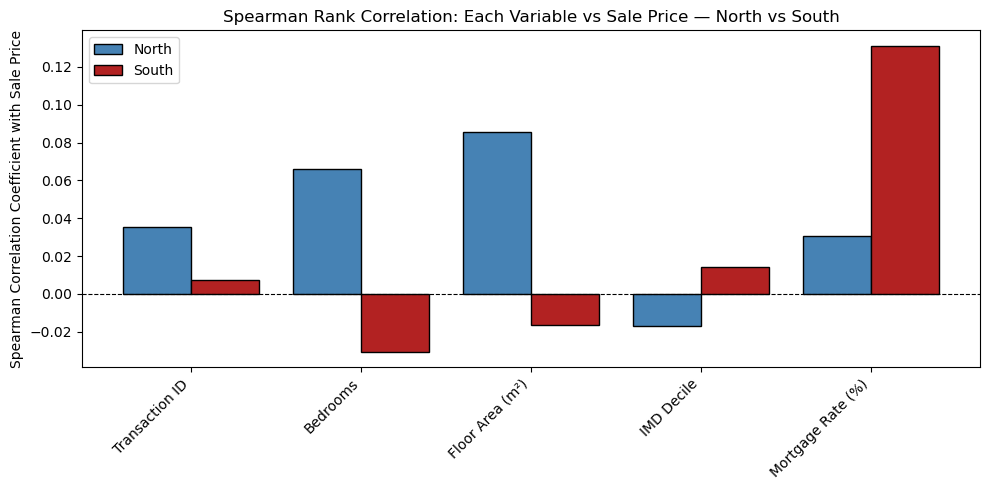

In [44]:
#same story in north, significant strong (almost perfect) correlation
#we will just use floor space when it comes to modelling now
#this is better anyway as it is a float variable rather than an integer variable.
#we will do and plot a spearmans rank correlation coefficient now on price vs all variables, for df_north and df_south

#code below generated by ai
corr_north = df_north.corr(method='spearman', numeric_only=True)
corr_south = df_south.corr(method='spearman', numeric_only=True)
price_corr_north = corr_north['Price_GBP']
price_corr_south = corr_south['Price_GBP']
north_vals = price_corr_north.drop('Price_GBP')
south_vals = price_corr_south.drop('Price_GBP')

x = range(len(north_vals))

plt.figure(figsize=(10, 5))
plt.bar(x, north_vals, width=0.4, label='North', color='steelblue', edgecolor='black')
plt.bar([i + 0.4 for i in x], south_vals, width=0.4, label='South', color='firebrick', edgecolor='black')

plt.xticks([i + 0.2 for i in x], ['Transaction ID', 'Bedrooms', 'Floor Area (m²)', 'IMD Decile', 'Mortgage Rate (%)'], rotation=45, ha='right')
plt.ylabel("Spearman Correlation Coefficient with Sale Price")
plt.title("Spearman Rank Correlation: Each Variable vs Sale Price — North vs South")
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.legend()
plt.tight_layout()
plt.show()

In [45]:
#data in the south just contradicts all intuitive thoughts on house price correlations
#data in north agrees with intuition
#nothing correlated at all really. 
#remind ourselves of the data we have.
print(df_north.info)
print(df_south.info)

<bound method DataFrame.info of      Transaction_ID       Date Region Local_Authority  Property_Type  \
0                 1 2019-06-14  North      Manchester  Semi-Detached   
1                 2 2015-03-25  North      Manchester  Semi-Detached   
2                 3 2017-07-23  North      Manchester       Detached   
3                 4 2022-03-08  North      Manchester       Detached   
4                 5 2021-12-24  North      Manchester       Terraced   
..              ...        ...    ...             ...            ...   
745             746 2020-06-19  North   Middlesbrough       Detached   
746             747 2016-05-01  North   Middlesbrough       Detached   
747             748 2023-12-09  North   Middlesbrough  Semi-Detached   
748             749 2021-11-26  North   Middlesbrough       Terraced   
749             750 2020-12-19  North   Middlesbrough       Detached   

       Tenure  Price_GBP  Floor_Area_m2  Number_of_Bedrooms  IMD_Decile  \
0    Freehold    88305.0    

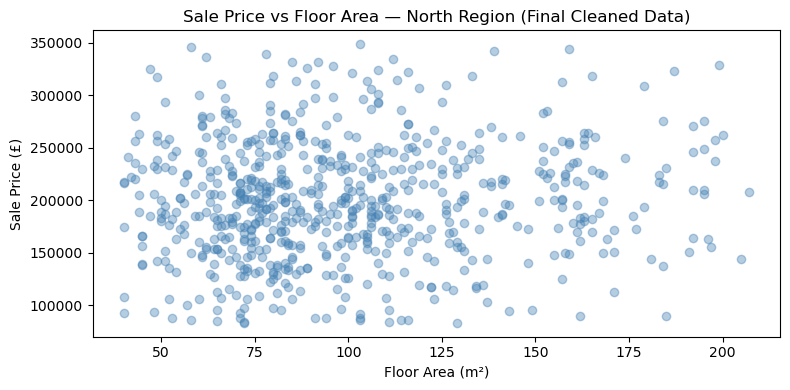

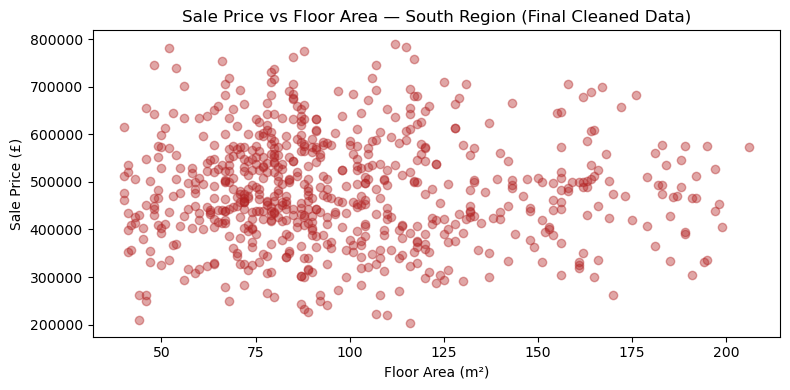

In [46]:
#were now gonna replot our data with new datasets. 
plt.figure(figsize=(8, 4))
plt.scatter(df_north['Floor_Area_m2'], df_north['Price_GBP'], alpha=0.4, color='steelblue')
plt.xlabel("Floor Area (m²)")
plt.ylabel("Sale Price (£)")
plt.title("Sale Price vs Floor Area — North Region (Final Cleaned Data)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.scatter(df_south['Floor_Area_m2'], df_south['Price_GBP'], alpha=0.4, color='firebrick')
plt.xlabel("Floor Area (m²)")
plt.ylabel("Sale Price (£)")
plt.title("Sale Price vs Floor Area — South Region (Final Cleaned Data)")
plt.tight_layout()
plt.show()

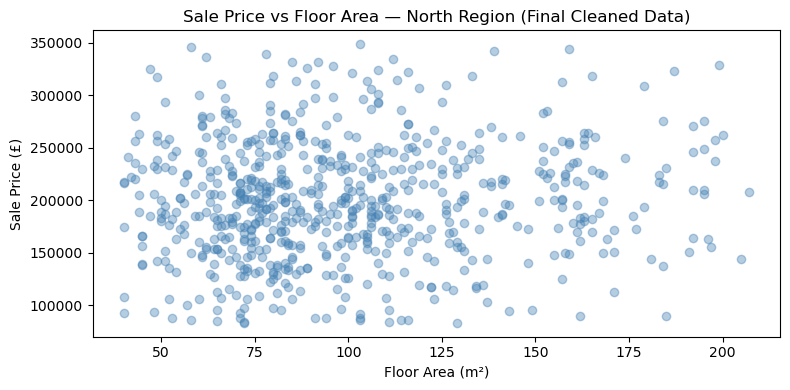

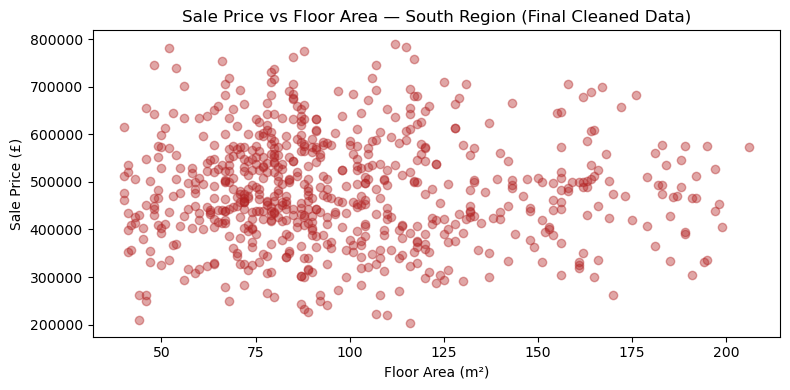

In [47]:
# duplicate scatter plots — kept for reference but identical to cell above.
plt.figure(figsize=(8, 4))
plt.scatter(df_north['Floor_Area_m2'], df_north['Price_GBP'], alpha=0.4, color='steelblue')
plt.xlabel("Floor Area (m²)")
plt.ylabel("Sale Price (£)")
plt.title("Sale Price vs Floor Area — North Region (Final Cleaned Data)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.scatter(df_south['Floor_Area_m2'], df_south['Price_GBP'], alpha=0.4, color='firebrick')
plt.xlabel("Floor Area (m²)")
plt.ylabel("Sale Price (£)")
plt.title("Sale Price vs Floor Area — South Region (Final Cleaned Data)")
plt.tight_layout()
plt.show()

In [48]:
#no obvious patterns. 
#try a multiple linear regression on price and then test assumptions. (likely disprove our assumptions.)
X_north = df_north[['Average_Mortgage_Rate_Percent', 'Floor_Area_m2',
'IMD_Decile']]
y_north = df_north['Price_GBP']
X_north = sm.add_constant(X_north)
north_mlr_model = sm.OLS(y_north, X_north).fit()
print(north_mlr_model.summary())


                            OLS Regression Results                            
Dep. Variable:              Price_GBP   R-squared:                       0.015
Model:                            OLS   Adj. R-squared:                  0.010
Method:                 Least Squares   F-statistic:                     3.405
Date:                Thu, 16 Apr 2026   Prob (F-statistic):             0.0174
Time:                        22:57:34   Log-Likelihood:                -8429.5
No. Observations:                 683   AIC:                         1.687e+04
Df Residuals:                     679   BIC:                         1.689e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [49]:
#nothings significant, model doesnt predict anything. 
#prob omnibus and prob jb tell us that the residuals are not normally distributed.
#we need to give categorical variables a rank and start modelling these. 
#encode these, remodel.
#code beyond this point all AI generated, with constant checking of results from user and consistent prompting for desired output. 
#odd thing may have been tweaked however initially generated by ai
df_north_encoded = pd.get_dummies(df_north, columns=['Local_Authority', 'Property_Type', 'Tenure'], drop_first=True)
X_north = df_north_encoded.drop(columns=['Price_GBP', 'Date', 'Region'])
y_north = df_north_encoded['Price_GBP']


In [50]:
np.asarray(X_north)
X_north = X_north.astype(int)

In [51]:
np.asarray(X_north)

array([[  1,  94,   3, ...,   1,   0,   0],
       [  2,  91,   2, ...,   1,   0,   0],
       [  3, 162,   4, ...,   0,   0,   0],
       ...,
       [748,  87,   2, ...,   1,   0,   0],
       [749,  86,   3, ...,   0,   1,   0],
       [750, 123,   3, ...,   0,   0,   0]])

In [52]:
X_north = sm.add_constant(X_north)
north_mlr_model = sm.OLS(y_north, X_north).fit()
print(north_mlr_model.summary()) # ai generated

                            OLS Regression Results                            
Dep. Variable:              Price_GBP   R-squared:                       0.050
Model:                            OLS   Adj. R-squared:                  0.026
Method:                 Least Squares   F-statistic:                     2.061
Date:                Thu, 16 Apr 2026   Prob (F-statistic):            0.00719
Time:                        22:57:35   Log-Likelihood:                -8417.0
No. Observations:                 683   AIC:                         1.687e+04
Df Residuals:                     665   BIC:                         1.695e+04
Df Model:                          17                                         
Covariance Type:            nonrobust                                         
                                          coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
co

In [53]:
#all have positive coeffiecients except for IMD_decile, this makes sense.
#only average mortgage rate and wether house is in bolton or not are significant factors. 
#not significant overall, prob(f-statistic) = 0.09...>0.05
#still no normal distribution prob (JB) = 0.0111 < 0.05, prob(omnibus) = 0.011 < 0.05
#We can already see multiple linear regression is a poor model choice, instead of trying to make it work, we move on.
df_south_encoded = pd.get_dummies(df_south, columns=['Local_Authority', 'Property_Type', 'Tenure'], drop_first=True)
X_south = df_south_encoded.drop(columns=['Price_GBP', 'Date', 'Region'])
y_south = df_south_encoded['Price_GBP']
X_south = X_south.astype(int)
X_south = sm.add_constant(X_south)
south_mlr_model = sm.OLS(y_south, X_south).fit()
print(south_mlr_model.summary())

                            OLS Regression Results                            
Dep. Variable:              Price_GBP   R-squared:                       0.098
Model:                            OLS   Adj. R-squared:                  0.075
Method:                 Least Squares   F-statistic:                     4.229
Date:                Thu, 16 Apr 2026   Prob (F-statistic):           3.19e-08
Time:                        22:57:35   Log-Likelihood:                -8842.1
No. Observations:                 680   AIC:                         1.772e+04
Df Residuals:                     662   BIC:                         1.780e+04
Df Model:                          17                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [54]:
#actually not awful for southern region, remove number of bedrooms for this, avoid multicolinearity
#also remove the most insignificant variables.

df_south_encoded = pd.get_dummies(df_south, columns=['Local_Authority', 'Property_Type', 'Tenure'], drop_first=True)
X_south = df_south_encoded.drop(columns=['Price_GBP', 'Date', 'Region', 'Number_of_Bedrooms', 'Transaction_ID', 'IMD_Decile'])
y_south = df_south_encoded['Price_GBP']
X_south = X_south.astype(int)
X_south = sm.add_constant(X_south)
south_mlr_model = sm.OLS(y_south, X_south).fit()
print(south_mlr_model.summary())

                            OLS Regression Results                            
Dep. Variable:              Price_GBP   R-squared:                       0.095
Model:                            OLS   Adj. R-squared:                  0.076
Method:                 Least Squares   F-statistic:                     4.979
Date:                Thu, 16 Apr 2026   Prob (F-statistic):           7.06e-09
Time:                        22:57:35   Log-Likelihood:                -8843.2
No. Observations:                 680   AIC:                         1.772e+04
Df Residuals:                     665   BIC:                         1.778e+04
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [55]:
#we will keep this model in mind when choosing a model for the southern region.
#hopefully be better options, would have to play around with this more if i choose this model. - logistic - MLR mix
#going to do time series analysis. - see what that shows me.
#code for this generated completely by ai, i didnt even have to change a variable name.

##comments below are also ai generated.
# Build monthly median price time series for each region
df_north_ts = df_north.copy()
df_north_ts['Date'] = pd.to_datetime(df_north_ts['Date'])
df_north_ts = df_north_ts.set_index('Date')
ts_north = df_north_ts['Price_GBP'].resample('MS').median()

df_south_ts = df_south.copy()
df_south_ts['Date'] = pd.to_datetime(df_south_ts['Date'])
df_south_ts = df_south_ts.set_index('Date')
ts_south = df_south_ts['Price_GBP'].resample('MS').median()

print('north first 5 months', ts_north.head())
print('south first 5 months', ts_south.head())

north first 5 months Date
2015-01-01    238296.0
2015-02-01    169546.0
2015-03-01    164533.0
2015-04-01    170027.0
2015-05-01    196094.0
Freq: MS, Name: Price_GBP, dtype: float64
south first 5 months Date
2015-01-01    403268.0
2015-02-01    390071.5
2015-03-01    415455.5
2015-04-01    351852.0
2015-05-01    357410.0
Freq: MS, Name: Price_GBP, dtype: float64


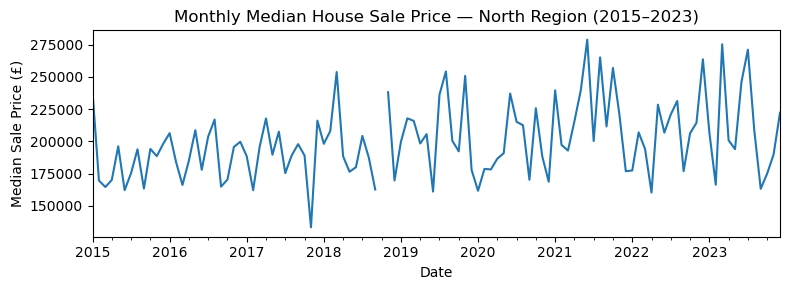

In [56]:
ax = ts_north.plot(figsize=(8, 3))
ax.set_title("Monthly Median House Sale Price — North Region (2015–2023)")
ax.set_xlabel("Date")
ax.set_ylabel("Median Sale Price (£)")
plt.tight_layout()
plt.show()

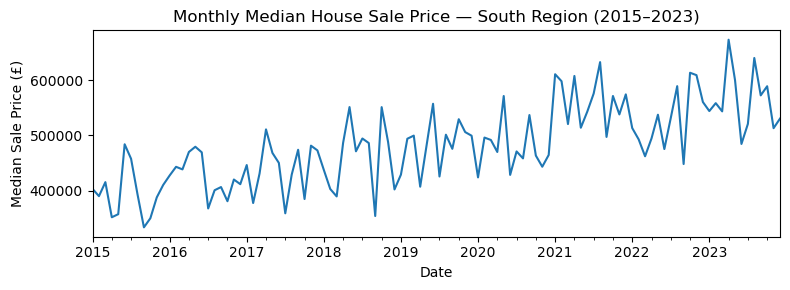

In [57]:
#break in data around end of 2018, this is not going to benefit us in any way, we use interpolation to fill data.
ts_north = df_north_ts['Price_GBP'].resample('MS').median()
ts_north = ts_north.interpolate(method='time')
#plot south now
ax = ts_south.plot(figsize=(8, 3))
ax.set_title("Monthly Median House Sale Price — South Region (2015–2023)")
ax.set_xlabel("Date")
ax.set_ylabel("Median Sale Price (£)")
plt.tight_layout()
plt.show()

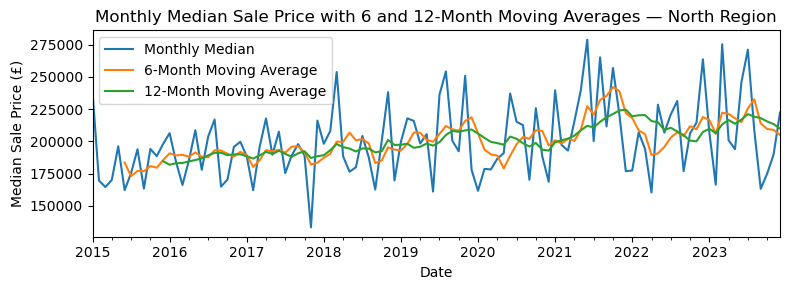

In [58]:
#this data looks nice. 
ts_north_ma = ts_north.to_frame()
ts_north_ma["ma_6"] = ts_north_ma["Price_GBP"].rolling(6).mean()
ts_north_ma["ma_12"] = ts_north_ma["Price_GBP"].rolling(12).mean()

ax = ts_north_ma[["Price_GBP", "ma_6", "ma_12"]].plot(figsize=(8, 3))
ax.set_title("Monthly Median Sale Price with 6 and 12-Month Moving Averages — North Region")
ax.set_xlabel("Date")
ax.set_ylabel("Median Sale Price (£)")
ax.legend(["Monthly Median", "6-Month Moving Average", "12-Month Moving Average"])
plt.tight_layout()
plt.show()

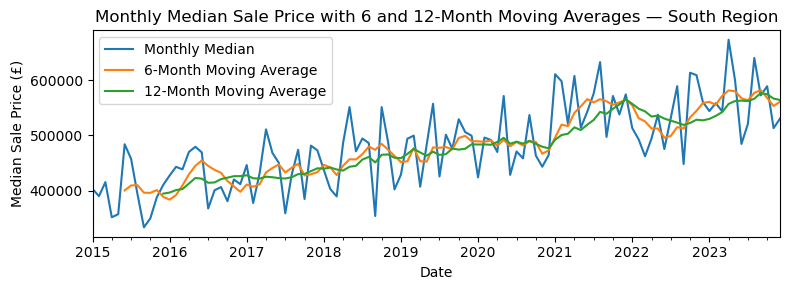

In [59]:
#getting a smoother graph now, almost detecting a trend here ?! Much better without gap

ts_south_ma = ts_south.to_frame()
ts_south_ma["ma_6"] = ts_south_ma["Price_GBP"].rolling(6).mean()
ts_south_ma["ma_12"] = ts_south_ma["Price_GBP"].rolling(12).mean()

ax = ts_south_ma[["Price_GBP", "ma_6", "ma_12"]].plot(figsize=(8, 3))
ax.set_title("Monthly Median Sale Price with 6 and 12-Month Moving Averages — South Region")
ax.set_xlabel("Date")
ax.set_ylabel("Median Sale Price (£)")
ax.legend(["Monthly Median", "6-Month Moving Average", "12-Month Moving Average"])
plt.tight_layout()
plt.show()

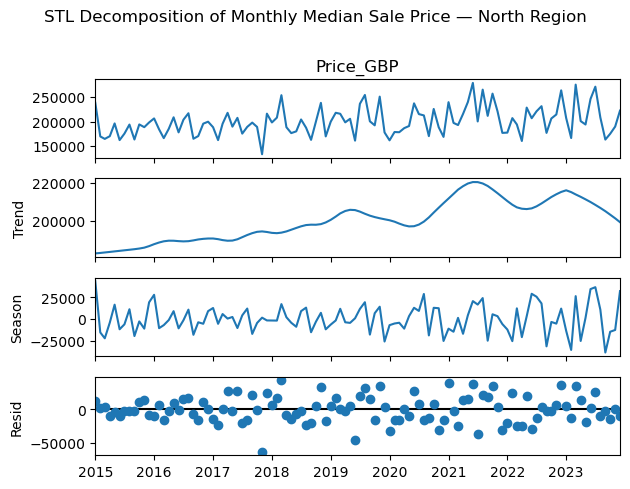

In [60]:
#seasonality time
# STL decomposes the series into Trend, Seasonal, and Residual components.
res_north = STL(ts_north, period=12).fit()
fig = res_north.plot()
fig.suptitle("STL Decomposition of Monthly Median Sale Price — North Region", y=1.01)
plt.tight_layout()
plt.show()

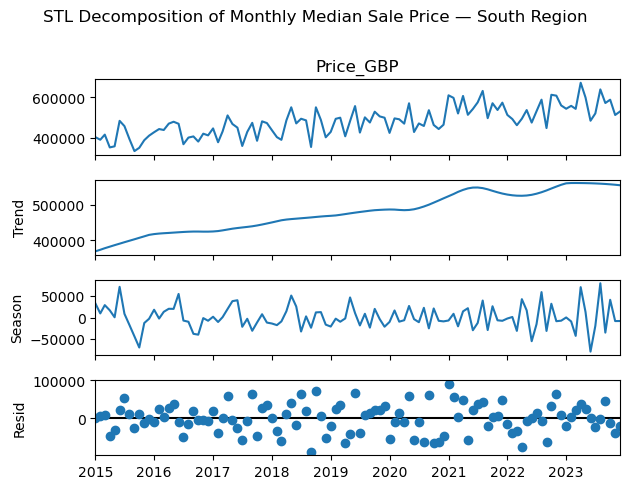

North seasonal strength score: 0.301  (>0.64 = strong seasonality, <0.64 = weak)
South seasonal strength score: 0.316  (>0.64 = strong seasonality, <0.64 = weak)


In [61]:
#trend still not linear, resid look random, possible slight funnel.
#i dont see obvious seasonality.
# STL decomposes the series into Trend, Seasonal, and Residual components.
res_south = STL(ts_south, period=12).fit()
fig = res_south.plot()
fig.suptitle("STL Decomposition of Monthly Median Sale Price — South Region", y=1.01)
plt.tight_layout()
plt.show()

# seasonal strength score: 0 = no seasonality, 1 = perfect seasonality.
# a score above 0.64 is considered meaningful seasonal behaviour.
# this gives a quantitative justification for choosing ARIMA over SARIMA.
for ts, label in [(ts_north, "North"), (ts_south, "South")]:
    stl = STL(ts, period=12, robust=True).fit()
    var_resid = np.var(stl.resid)
    var_season_resid = np.var(stl.seasonal + stl.resid)
    strength = max(0, 1 - var_resid / var_season_resid)
    print(f"{label} seasonal strength score: {strength:.3f}  (>0.64 = strong seasonality, <0.64 = weak)")

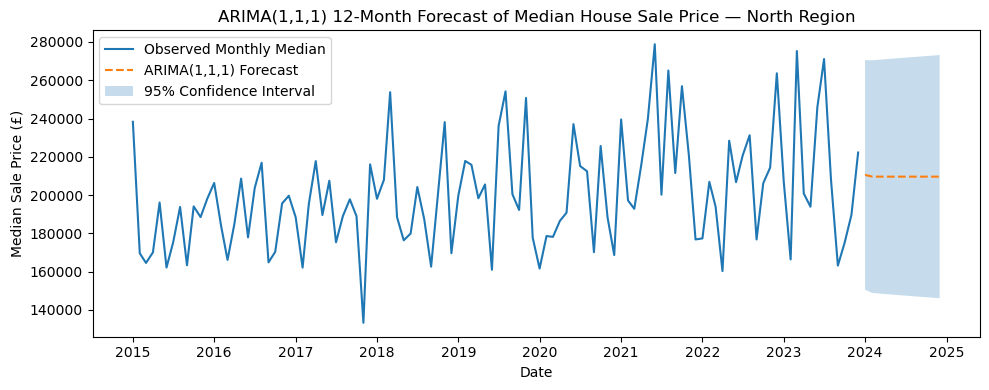

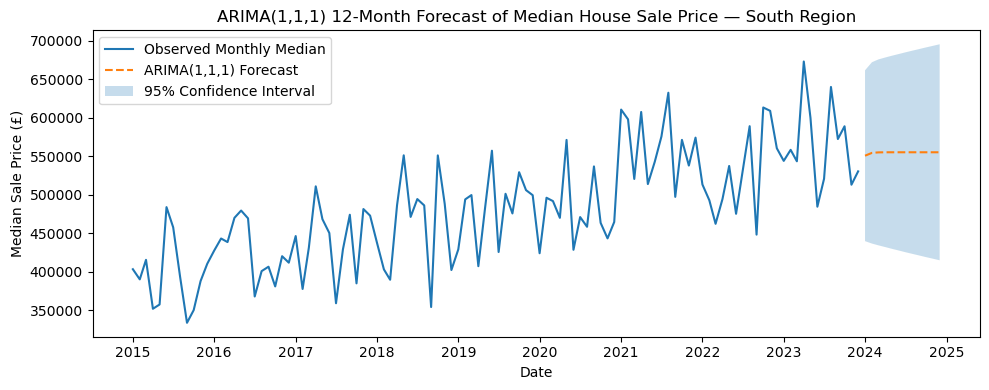

In [62]:
#May have to use arima as opposed to original plan to do sarima, i see no obvious seasonality aspect.
#residuals funnel
#trendline is non linear. 
#no consistent seasonal pattern.

#all time series code was generated by ai.

from statsmodels.tsa.statespace.sarimax import SARIMAX

h = 12
future_index_north = pd.date_range(ts_north.index[-1] + pd.DateOffset(months=1), periods=h, freq='MS')
future_index_south = pd.date_range(ts_south.index[-1] + pd.DateOffset(months=1), periods=h, freq='MS')

arima_north = SARIMAX(ts_north, order=(1, 1, 1), seasonal_order=(0, 0, 0, 0)).fit(disp=False)
arima_obj_north = arima_north.get_forecast(steps=h)
arima_fc_north = arima_obj_north.predicted_mean
arima_fc_north.index = future_index_north
arima_ci_north = arima_obj_north.conf_int(alpha=0.05)
arima_ci_north.index = future_index_north

arima_south = SARIMAX(ts_south, order=(1, 1, 1), seasonal_order=(0, 0, 0, 0)).fit(disp=False)
arima_obj_south = arima_south.get_forecast(steps=h)
arima_fc_south = arima_obj_south.predicted_mean
arima_fc_south.index = future_index_south
arima_ci_south = arima_obj_south.conf_int(alpha=0.05)
arima_ci_south.index = future_index_south

plt.figure(figsize=(10, 4))
plt.plot(ts_north, label="Observed Monthly Median")
plt.plot(arima_fc_north, label="ARIMA(1,1,1) Forecast", linestyle='--')
plt.fill_between(arima_ci_north.index, arima_ci_north.iloc[:, 0], arima_ci_north.iloc[:, 1], alpha=0.25, label="95% Confidence Interval")
plt.xlabel("Date")
plt.ylabel("Median Sale Price (£)")
plt.legend()
plt.title(f"ARIMA(1,1,1) 12-Month Forecast of Median House Sale Price — North Region")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(ts_south, label="Observed Monthly Median")
plt.plot(arima_fc_south, label="ARIMA(1,1,1) Forecast", linestyle='--')
plt.fill_between(arima_ci_south.index, arima_ci_south.iloc[:, 0], arima_ci_south.iloc[:, 1], alpha=0.25, label="95% Confidence Interval")
plt.xlabel("Date")
plt.ylabel("Median Sale Price (£)")
plt.legend()
plt.title(f"ARIMA(1,1,1) 12-Month Forecast of Median House Sale Price — South Region")
plt.tight_layout()
plt.show()

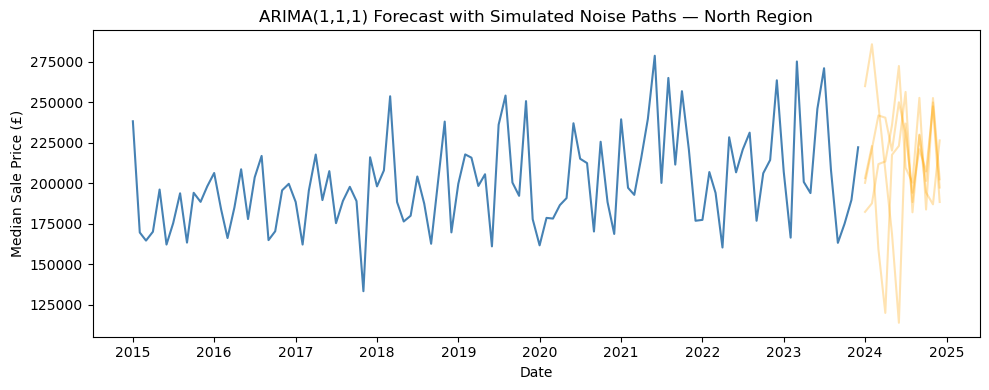

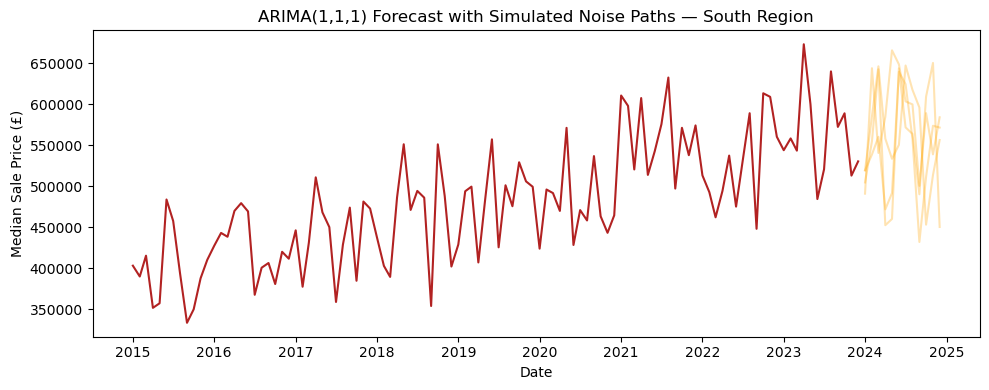

In [63]:
#add some noise
# each simulated path adds random noise scaled to the model's residual standard deviation,
# showing the range of plausible future outcomes rather than a single deterministic line.
n_sim = 4

plt.figure(figsize=(10, 4))
plt.plot(ts_north, label="Observed Monthly Median", color='steelblue')
for path in arima_fc_north.values + np.random.normal(0, arima_north.resid.std(), (n_sim, h)):
    plt.plot(future_index_north, path, alpha=0.3, color='orange')
plt.xlabel("Date")
plt.ylabel("Median Sale Price (£)")
plt.title("ARIMA(1,1,1) Forecast with Simulated Noise Paths — North Region")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(ts_south, label="Observed Monthly Median", color='firebrick')
for path in arima_fc_south.values + np.random.normal(0, arima_south.resid.std(), (n_sim, h)):
    plt.plot(future_index_south, path, alpha=0.3, color='orange')
plt.xlabel("Date")
plt.ylabel("Median Sale Price (£)")
plt.title("ARIMA(1,1,1) Forecast with Simulated Noise Paths — South Region")
plt.tight_layout()
plt.show()

In [64]:
#way better than sarima, much less variance. 
#include in what graphs mean in marketing. 
#all model evaluation is AI generated. 
test_months = 12  # hold out last 12 months as test set

train_north = ts_north.iloc[:-test_months]
test_north  = ts_north.iloc[-test_months:]
test_dates_north = test_north.index

train_south = ts_south.iloc[:-test_months]
test_south  = ts_south.iloc[-test_months:]
test_dates_south = test_south.index

print(f"North — train: {len(train_north)} months, test: {len(test_north)} months")
print(f"South — train: {len(train_south)} months, test: {len(test_south)} months")

North — train: 96 months, test: 12 months
South — train: 96 months, test: 12 months


In [65]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

arima_train_north = SARIMAX(train_north, order=(1,1,1), seasonal_order=(0,0,0,0)).fit(disp=False)
pred_north = arima_train_north.forecast(steps=test_months).to_numpy()

arima_train_south = SARIMAX(train_south, order=(1,1,1), seasonal_order=(0,0,0,0)).fit(disp=False)
pred_south = arima_train_south.forecast(steps=test_months).to_numpy()

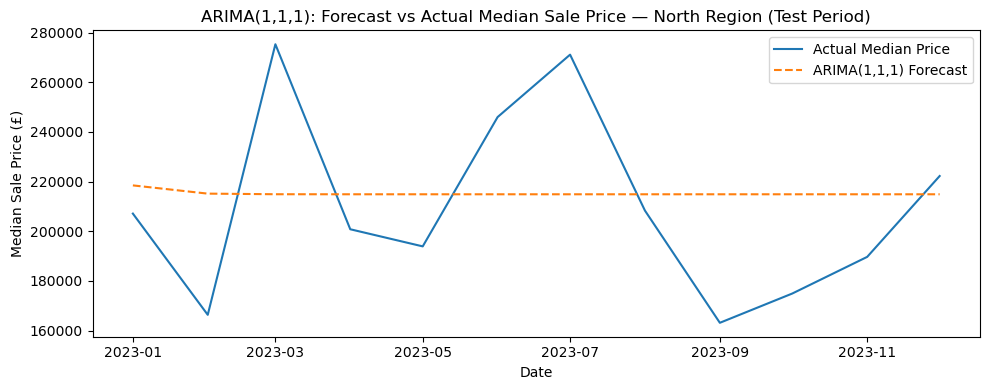

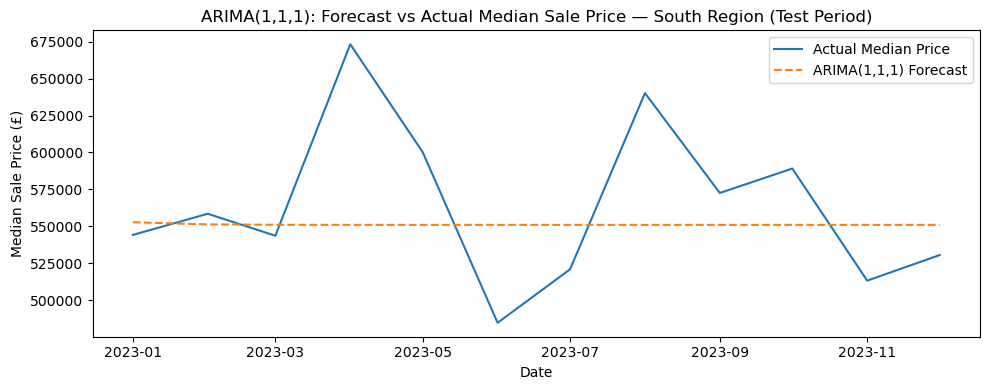

In [66]:
plt.figure(figsize=(10, 4))
plt.plot(test_dates_north, test_north, label="Actual Median Price")
plt.plot(test_dates_north, pred_north, label="ARIMA(1,1,1) Forecast", linestyle='--')
plt.title("ARIMA(1,1,1): Forecast vs Actual Median Sale Price — North Region (Test Period)")
plt.xlabel("Date")
plt.ylabel("Median Sale Price (£)")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(test_dates_south, test_south, label="Actual Median Price")
plt.plot(test_dates_south, pred_south, label="ARIMA(1,1,1) Forecast", linestyle='--')
plt.title("ARIMA(1,1,1): Forecast vs Actual Median Sale Price — South Region (Test Period)")
plt.xlabel("Date")
plt.ylabel("Median Sale Price (£)")
plt.legend()
plt.tight_layout()
plt.show()

In [67]:
#predicts average value, not 'moving average' as wanted. 
mae_north  = mean_absolute_error(test_north, pred_north)
rmse_north = mean_squared_error(test_north, pred_north) ** 0.5

mae_south  = mean_absolute_error(test_south, pred_south)
rmse_south = mean_squared_error(test_south, pred_south) ** 0.5

results = pd.DataFrame({
    "model":  ["ARIMA (1,1,1)", "ARIMA (1,1,1)"],
    "region": ["North", "South"],
    "MAE":    [mae_north, mae_south],
    "RMSE":   [rmse_north, rmse_south]
})
print(results)

           model region           MAE          RMSE
0  ARIMA (1,1,1)  North  31139.294470  36426.175371
1  ARIMA (1,1,1)  South  41543.476681  53715.115800


In [68]:
#honestly, data doesnt show enough of a trend over time to be using time series.
#random forest
# encode categoricals and drop columns RF can't use
df_north_rf = pd.get_dummies(df_north, columns=['Property_Type', 'Tenure', 'Local_Authority'], drop_first=True)
df_south_rf = pd.get_dummies(df_south, columns=['Property_Type', 'Tenure', 'Local_Authority'], drop_first=True)

# extract year and month from date as numeric features, then drop date
for df_rf in [df_north_rf, df_south_rf]:
    df_rf['Year']  = df_rf['Date'].dt.year
    df_rf['Month'] = df_rf['Date'].dt.month

y_north = df_north_rf['Price_GBP']
X_north = df_north_rf.drop(columns=['Price_GBP', 'Date', 'Region', 'Transaction_ID'])

y_south = df_south_rf['Price_GBP']
X_south = df_south_rf.drop(columns=['Price_GBP', 'Date', 'Region', 'Transaction_ID'])

print(X_north.head())
print(X_north.columns.tolist())

   Floor_Area_m2  Number_of_Bedrooms  IMD_Decile  \
0           94.0                 3.0         5.0   
1           91.0                 2.0         4.0   
2          162.0                 4.0         5.0   
3          152.0                 4.0         8.0   
4           79.0                 2.0         5.0   

   Average_Mortgage_Rate_Percent  Property_Type_Flat  \
0                           2.18               False   
1                           2.56               False   
2                           2.06               False   
3                           3.41               False   
4                           2.16               False   

   Property_Type_Semi-Detached  Property_Type_Terraced  Tenure_Leasehold  \
0                         True                   False             False   
1                         True                   False             False   
2                        False                   False             False   
3                        False                

In [69]:
#formatted perfectly for random forest, this could be our first chance at an appropriate model. 
# sort by date first so the split is chronological, not random
df_north_rf = df_north_rf.sort_values('Date')
df_south_rf = df_south_rf.sort_values('Date')

test_n = int(len(df_north_rf) * 0.2)
test_s = int(len(df_south_rf) * 0.2)

X_train_north = X_north.iloc[:-test_n]
y_train_north = y_north.iloc[:-test_n]
X_test_north  = X_north.iloc[-test_n:]
y_test_north  = y_north.iloc[-test_n:]

X_train_south = X_south.iloc[:-test_s]
y_train_south = y_south.iloc[:-test_s]
X_test_south  = X_south.iloc[-test_s:]
y_test_south  = y_south.iloc[-test_s:]

print(f"North — train: {len(X_train_north)}, test: {len(X_test_north)}")
print(f"South — train: {len(X_train_south)}, test: {len(X_test_south)}")

North — train: 547, test: 136
South — train: 544, test: 136


In [70]:
model_north = RandomForestRegressor(n_estimators=200, random_state=42)
model_north.fit(X_train_north, y_train_north)
pred_north = model_north.predict(X_test_north)

model_south = RandomForestRegressor(n_estimators=200, random_state=42)
model_south.fit(X_train_south, y_train_south)
pred_south = model_south.predict(X_test_south)

print("North — MAE:",  round(mean_absolute_error(y_test_north, pred_north), 2))
print("North — RMSE:", round(mean_squared_error(y_test_north, pred_north)**0.5, 2))
print("South — MAE:",  round(mean_absolute_error(y_test_south, pred_south), 2))
print("South — RMSE:", round(mean_squared_error(y_test_south, pred_south)**0.5, 2))

North — MAE: 46775.45
North — RMSE: 56666.46
South — MAE: 80894.63
South — RMSE: 101128.78


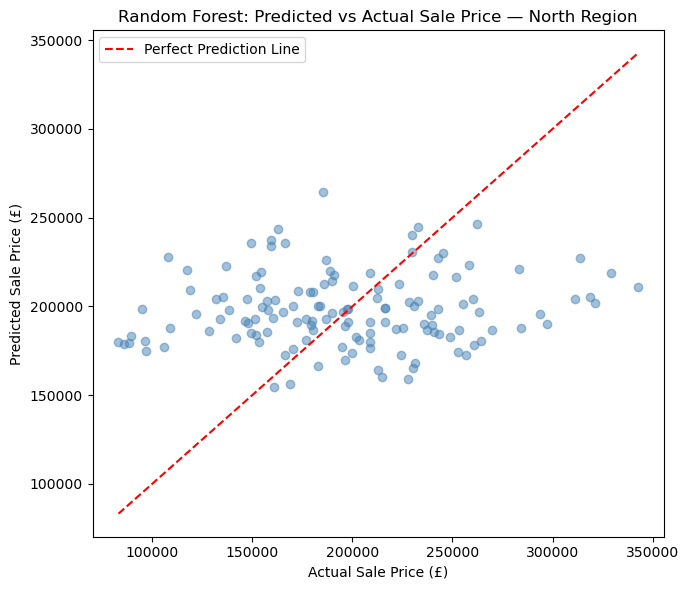

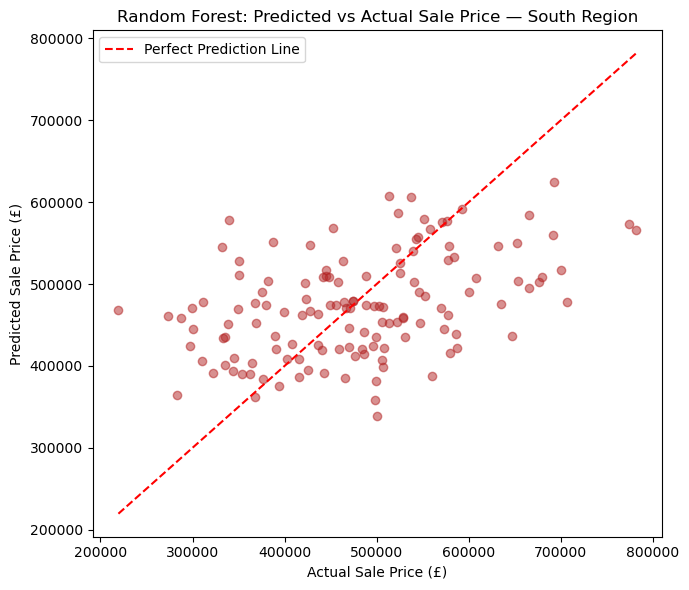

In [71]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test_north, pred_north, alpha=0.5, color='steelblue')
plt.plot([y_test_north.min(), y_test_north.max()],
         [y_test_north.min(), y_test_north.max()], 'r--', label='Perfect Prediction Line')
plt.xlabel("Actual Sale Price (£)")
plt.ylabel("Predicted Sale Price (£)")
plt.title("Random Forest: Predicted vs Actual Sale Price — North Region")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 6))
plt.scatter(y_test_south, pred_south, alpha=0.5, color='firebrick')
plt.plot([y_test_south.min(), y_test_south.max()],
         [y_test_south.min(), y_test_south.max()], 'r--', label='Perfect Prediction Line')
plt.xlabel("Actual Sale Price (£)")
plt.ylabel("Predicted Sale Price (£)")
plt.title("Random Forest: Predicted vs Actual Sale Price — South Region")
plt.legend()
plt.tight_layout()
plt.show()

In [72]:
from sklearn.ensemble import GradientBoostingRegressor

# fit gradient boosting
model_GB_north = GradientBoostingRegressor(n_estimators=200, random_state=42)
model_GB_north.fit(X_train_north, y_train_north)
pred_GB_north = model_GB_north.predict(X_test_north)

model_GB_south = GradientBoostingRegressor(n_estimators=200, random_state=42)
model_GB_south.fit(X_train_south, y_train_south)
pred_GB_south = model_GB_south.predict(X_test_south)

print("GB North — MAE:", round(mean_absolute_error(y_test_north, pred_GB_north), 2))
print("GB North — RMSE:", round(mean_squared_error(y_test_north, pred_GB_north)**0.5, 2))
print("GB South — MAE:", round(mean_absolute_error(y_test_south, pred_GB_south), 2))
print("GB South — RMSE:", round(mean_squared_error(y_test_south, pred_GB_south)**0.5, 2))

GB North — MAE: 47935.53
GB North — RMSE: 58934.63
GB South — MAE: 80098.68
GB South — RMSE: 99866.9


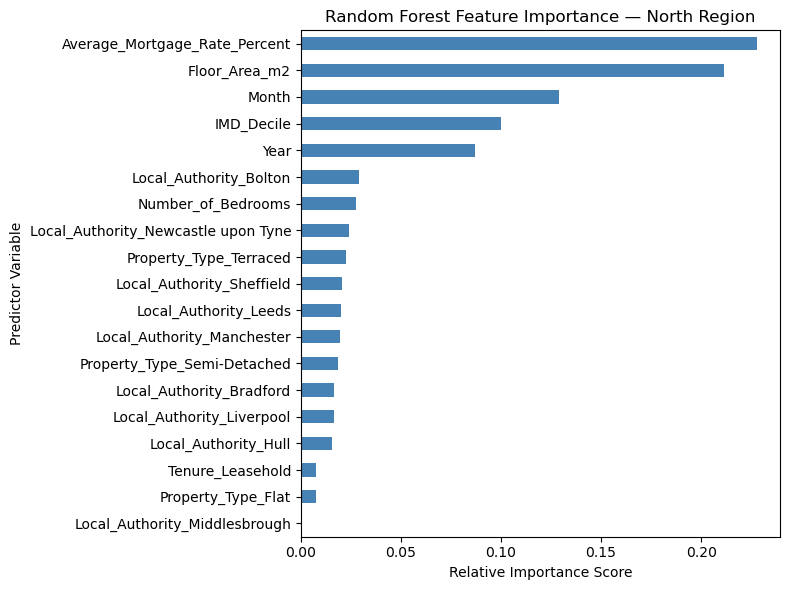

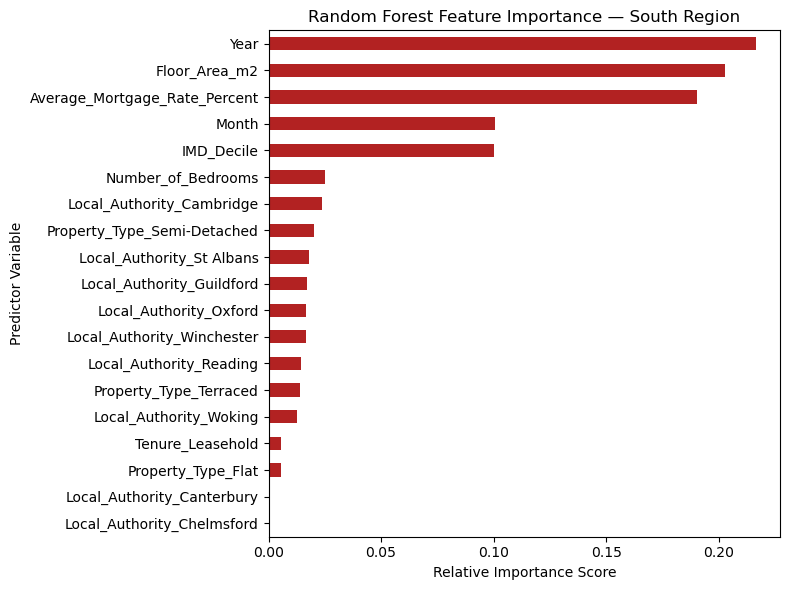

In [73]:
importances_north = pd.Series(model_north.feature_importances_, index=X_north.columns).sort_values(ascending=True)
importances_south = pd.Series(model_south.feature_importances_, index=X_south.columns).sort_values(ascending=True)

importances_north.plot(kind='barh', figsize=(8, 6), color='steelblue', title="Random Forest Feature Importance — North Region")
plt.xlabel("Relative Importance Score")
plt.ylabel("Predictor Variable")
plt.tight_layout()
plt.show()

importances_south.plot(kind='barh', figsize=(8, 6), color='firebrick', title="Random Forest Feature Importance — South Region")
plt.xlabel("Relative Importance Score")
plt.ylabel("Predictor Variable")
plt.tight_layout()
plt.show()

North RF  — mean MAE: £47,152  std: £365
North GB  — mean MAE: £47,936  std: £177
South RF  — mean MAE: £80,517  std: £505
South GB  — mean MAE: £80,143  std: £232


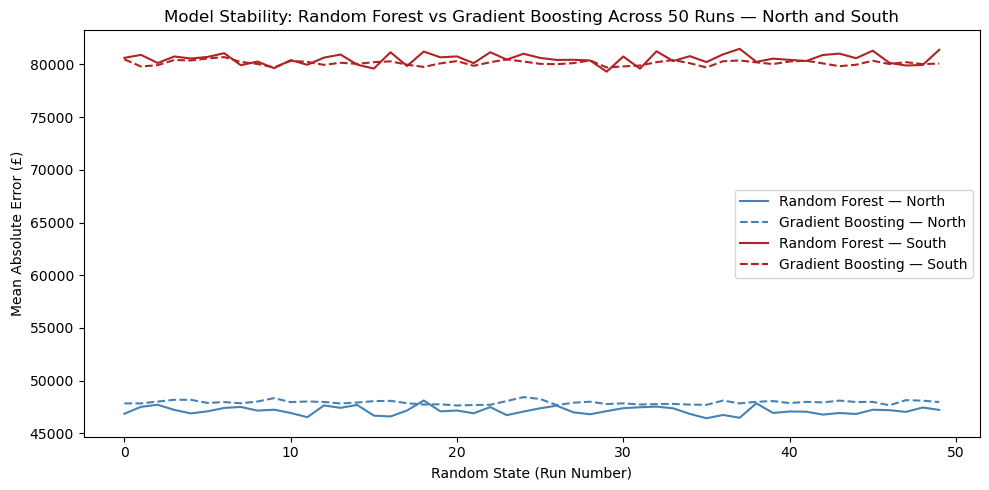

      Model Mean MAE Std MAE
0  RF North  £47,152    £365
1  GB North  £47,936    £177
2  RF South  £80,517    £505
3  GB South  £80,143    £232


In [74]:
#probably most accurate so far, however points are actually quite far from line still meaning predictions not fantastic
#worked better in south than north.
rep_mae_rf_north = []
rep_mae_gb_north = []
rep_mae_rf_south = []
rep_mae_gb_south = []

for i in range(50):
    rf_n = RandomForestRegressor(n_estimators=200, random_state=i)
    rf_n.fit(X_train_north, y_train_north)
    rep_mae_rf_north.append(mean_absolute_error(y_test_north, rf_n.predict(X_test_north)))

    gb_n = GradientBoostingRegressor(n_estimators=200, random_state=i)
    gb_n.fit(X_train_north, y_train_north)
    rep_mae_gb_north.append(mean_absolute_error(y_test_north, gb_n.predict(X_test_north)))

    rf_s = RandomForestRegressor(n_estimators=200, random_state=i)
    rf_s.fit(X_train_south, y_train_south)
    rep_mae_rf_south.append(mean_absolute_error(y_test_south, rf_s.predict(X_test_south)))

    gb_s = GradientBoostingRegressor(n_estimators=200, random_state=i)
    gb_s.fit(X_train_south, y_train_south)
    rep_mae_gb_south.append(mean_absolute_error(y_test_south, gb_s.predict(X_test_south)))

# print mean and std MAE across all 50 runs — more reliable than a single run result
print("North RF  — mean MAE: £{:,.0f}  std: £{:,.0f}".format(np.mean(rep_mae_rf_north), np.std(rep_mae_rf_north)))
print("North GB  — mean MAE: £{:,.0f}  std: £{:,.0f}".format(np.mean(rep_mae_gb_north), np.std(rep_mae_gb_north)))
print("South RF  — mean MAE: £{:,.0f}  std: £{:,.0f}".format(np.mean(rep_mae_rf_south), np.std(rep_mae_rf_south)))
print("South GB  — mean MAE: £{:,.0f}  std: £{:,.0f}".format(np.mean(rep_mae_gb_south), np.std(rep_mae_gb_south)))

plt.figure(figsize=(10, 5))
plt.plot(rep_mae_rf_north, label="Random Forest — North", color='steelblue')
plt.plot(rep_mae_gb_north, label="Gradient Boosting — North", color='steelblue', linestyle='--')
plt.plot(rep_mae_rf_south, label="Random Forest — South", color='firebrick')
plt.plot(rep_mae_gb_south, label="Gradient Boosting — South", color='firebrick', linestyle='--')
plt.xlabel("Random State (Run Number)")
plt.ylabel("Mean Absolute Error (£)")
plt.title("Model Stability: Random Forest vs Gradient Boosting Across 50 Runs — North and South")
plt.legend()
plt.tight_layout()
plt.show()

print(pd.DataFrame({
    "Model":  ["RF North", "GB North", "RF South", "GB South"],
    "Mean MAE": [f"£{np.mean(rep_mae_rf_north):,.0f}", f"£{np.mean(rep_mae_gb_north):,.0f}",
                 f"£{np.mean(rep_mae_rf_south):,.0f}", f"£{np.mean(rep_mae_gb_south):,.0f}"],
    "Std MAE":  [f"£{np.std(rep_mae_rf_north):,.0f}",  f"£{np.std(rep_mae_gb_north):,.0f}",
                 f"£{np.std(rep_mae_rf_south):,.0f}",  f"£{np.std(rep_mae_gb_south):,.0f}"]
}))

In [75]:
#these are relatively flat across these values hence these error values are probably accurate, south has higher variance. 
#these variances are so massive compared to the mean values, (roughly 30%) this suggests
#i think were gonna have to go back to our mlr and make the original tweaks, no model seems to work amazingly.
#this can often be case with human behaviour, can talk about in right up. 
df_north_enc = pd.get_dummies(df_north, columns=['Property_Type', 'Tenure', 'Local_Authority'], drop_first=True)
df_south_enc = pd.get_dummies(df_south, columns=['Property_Type', 'Tenure', 'Local_Authority'], drop_first=True)

for df_enc in [df_north_enc, df_south_enc]:
    bool_cols = df_enc.select_dtypes(include='bool').columns
    df_enc[bool_cols] = df_enc[bool_cols].astype(int)

# add squared floor area term to South to address nonlinearity identified by RESET test
# a squared term allows the model to capture diminishing returns on floor area
df_south_enc['Floor_Area_m2_sq'] = df_south_enc['Floor_Area_m2'] ** 2

# drop Number_of_Bedrooms — multicollinearity with Floor_Area_m2 confirmed earlier
y_north = df_north_enc['Price_GBP']
X_north = df_north_enc.drop(columns=['Price_GBP', 'Date', 'Region', 'Transaction_ID', 'Number_of_Bedrooms'])

y_south = df_south_enc['Price_GBP']
X_south = df_south_enc.drop(columns=['Price_GBP', 'Date', 'Region', 'Transaction_ID', 'Number_of_Bedrooms'])

print("North features:", X_north.columns.tolist())
print("South features:", X_south.columns.tolist())

North features: ['Floor_Area_m2', 'IMD_Decile', 'Average_Mortgage_Rate_Percent', 'Property_Type_Flat', 'Property_Type_Semi-Detached', 'Property_Type_Terraced', 'Tenure_Leasehold', 'Local_Authority_Bolton', 'Local_Authority_Bradford', 'Local_Authority_Hull', 'Local_Authority_Leeds', 'Local_Authority_Liverpool', 'Local_Authority_Manchester', 'Local_Authority_Middlesbrough', 'Local_Authority_Newcastle upon Tyne', 'Local_Authority_Sheffield']
South features: ['Floor_Area_m2', 'IMD_Decile', 'Average_Mortgage_Rate_Percent', 'Property_Type_Flat', 'Property_Type_Semi-Detached', 'Property_Type_Terraced', 'Tenure_Leasehold', 'Local_Authority_Cambridge', 'Local_Authority_Canterbury', 'Local_Authority_Chelmsford', 'Local_Authority_Guildford', 'Local_Authority_Oxford', 'Local_Authority_Reading', 'Local_Authority_St Albans', 'Local_Authority_Winchester', 'Local_Authority_Woking', 'Floor_Area_m2_sq']


In [76]:
X_north_const = sm.add_constant(X_north)
mlr_north = sm.OLS(y_north, X_north_const).fit()
print(mlr_north.summary())

X_south_const = sm.add_constant(X_south)
mlr_south = sm.OLS(y_south, X_south_const).fit()
print(mlr_south.summary())

# refit both models with HC3 robust standard errors to correct for heteroscedasticity
# HC3 adjusts standard errors without changing the coefficients themselves
mlr_north_robust = sm.OLS(y_north, X_north_const).fit(cov_type='HC3')
mlr_south_robust = sm.OLS(y_south, X_south_const).fit(cov_type='HC3')
print("\n--- North MLR with HC3 Robust Standard Errors ---")
print(mlr_north_robust.summary())
print("\n--- South MLR with HC3 Robust Standard Errors ---")
print(mlr_south_robust.summary())

                            OLS Regression Results                            
Dep. Variable:              Price_GBP   R-squared:                       0.043
Model:                            OLS   Adj. R-squared:                  0.022
Method:                 Least Squares   F-statistic:                     2.014
Date:                Thu, 16 Apr 2026   Prob (F-statistic):             0.0126
Time:                        23:05:13   Log-Likelihood:                -8419.4
No. Observations:                 683   AIC:                         1.687e+04
Df Residuals:                     667   BIC:                         1.694e+04
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
                                          coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
co

C:\Users\grego\anaconda3\Lib\site-packages\statsmodels\base\model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 16, but rank is 15
  warnings.warn('covariance of constraints does not have full '
C:\Users\grego\anaconda3\Lib\site-packages\statsmodels\base\model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 17, but rank is 16
  warnings.warn('covariance of constraints does not have full '


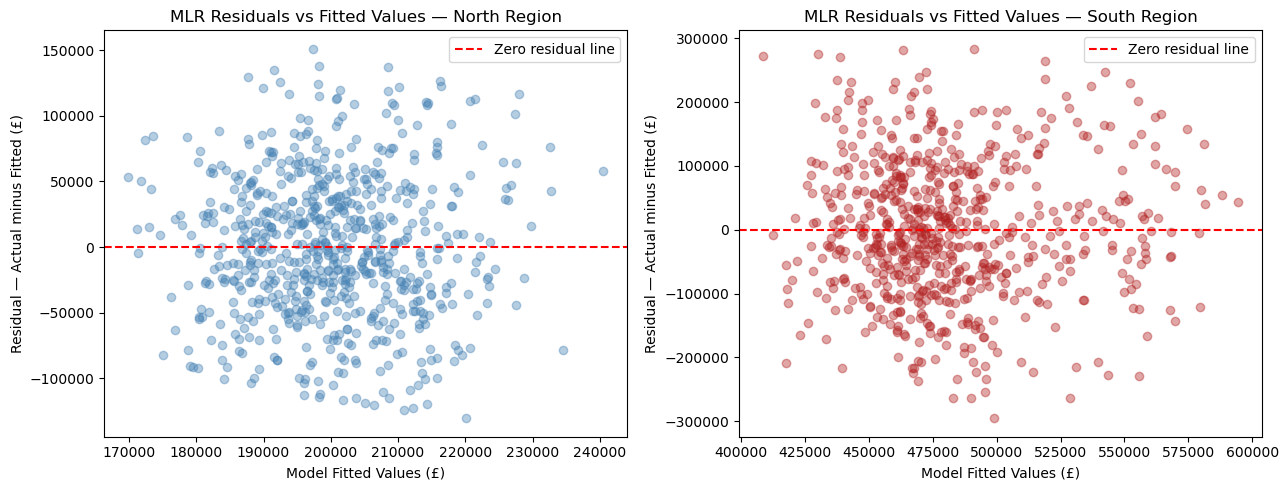

In [77]:
fitted_north = mlr_north.fittedvalues
resid_north  = mlr_north.resid

fitted_south = mlr_south.fittedvalues
resid_south  = mlr_south.resid

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(fitted_north, resid_north, alpha=0.4, color='steelblue')
axes[0].axhline(0, color='red', linestyle='--', label='Zero residual line')
axes[0].set_xlabel("Model Fitted Values (£)")
axes[0].set_ylabel("Residual — Actual minus Fitted (£)")
axes[0].set_title("MLR Residuals vs Fitted Values — North Region")
axes[0].legend()

axes[1].scatter(fitted_south, resid_south, alpha=0.4, color='firebrick')
axes[1].axhline(0, color='red', linestyle='--', label='Zero residual line')
axes[1].set_xlabel("Model Fitted Values (£)")
axes[1].set_ylabel("Residual — Actual minus Fitted (£)")
axes[1].set_title("MLR Residuals vs Fitted Values — South Region")
axes[1].legend()
plt.tight_layout()
plt.show()

Shapiro-Wilk test (H0: residuals are normal)
  North: p = 0.0389  ✗ reject normality
  South: p = 0.1534  ✓ cannot reject normality


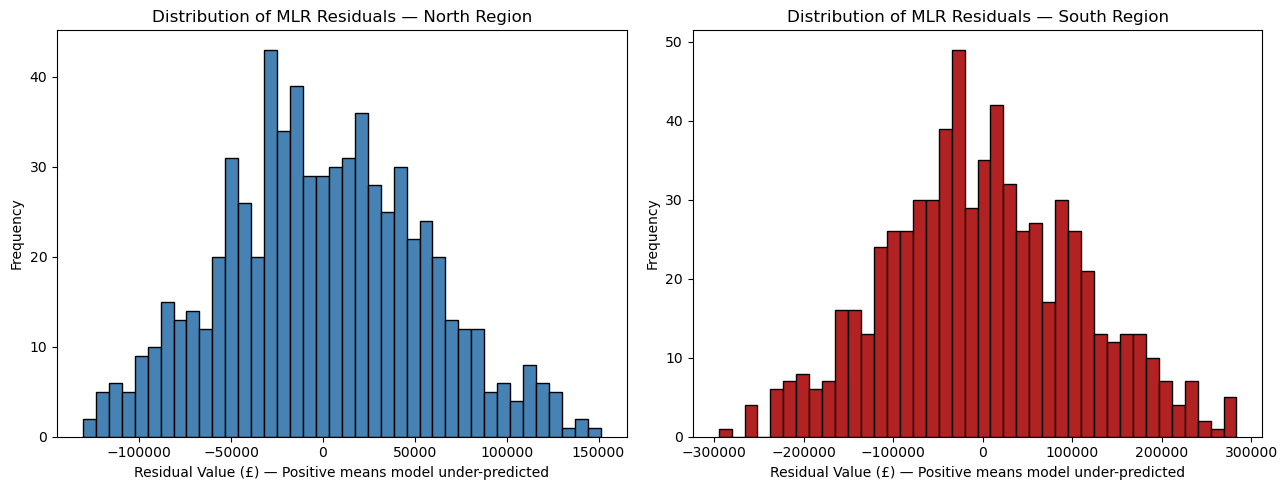

In [78]:
#see residuals dont look randon, sort of cluster in the middle

#normality test.
stat_n, p_n = stats.shapiro(resid_north)
stat_s, p_s = stats.shapiro(resid_south)

print("Shapiro-Wilk test (H0: residuals are normal)")
print(f"  North: p = {p_n:.4f}  {'✓ cannot reject normality' if p_n > 0.05 else '✗ reject normality'}")
print(f"  South: p = {p_s:.4f}  {'✓ cannot reject normality' if p_s > 0.05 else '✗ reject normality'}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(resid_north, bins=40, edgecolor='black', color='steelblue')
axes[0].set_title("Distribution of MLR Residuals — North Region")
axes[0].set_xlabel("Residual Value (£) — Positive means model under-predicted")
axes[0].set_ylabel("Frequency")

axes[1].hist(resid_south, bins=40, edgecolor='black', color='firebrick')
axes[1].set_title("Distribution of MLR Residuals — South Region")
axes[1].set_xlabel("Residual Value (£) — Positive means model under-predicted")
axes[1].set_ylabel("Frequency")
plt.tight_layout()
plt.show()

In [79]:
#residuals not normally distributed in north
#residuals normally distributed in south.
# H0: residuals have constant variance (homoscedastic)
bp_stat_n, bp_p_n, _, _ = het_breuschpagan(resid_north, X_north_const)
bp_stat_s, bp_p_s, _, _ = het_breuschpagan(resid_south, X_south_const)

print("Breusch-Pagan test (H0: homoscedasticity)")
print(f"  North: p = {bp_p_n:.4f}  {'✓ homoscedastic' if bp_p_n > 0.05 else '✗ heteroscedastic — HC3 robust standard errors applied in cell above'}")
print(f"  South: p = {bp_p_s:.4f}  {'✓ homoscedastic' if bp_p_s > 0.05 else '✗ heteroscedastic — HC3 robust standard errors applied in cell above'}")

Breusch-Pagan test (H0: homoscedasticity)
  North: p = 0.5764  ✓ homoscedastic
  South: p = 0.6343  ✓ homoscedastic


In [80]:
# H0: the model is correctly specified as linear
# if rejected for South, the Floor_Area_m2_sq term added in cell 75 is intended to address this
reset_n = linear_reset(mlr_north, power=2, use_f=True)
reset_s = linear_reset(mlr_south, power=2, use_f=True)

print("RESET test (H0: model is linear)")
print(f"  North: p = {reset_n.pvalue:.4f}  {'✓ linear' if reset_n.pvalue > 0.05 else '✗ non-linear relationship present'}")
print(f"  South: p = {reset_s.pvalue:.4f}  {'✓ linear — Floor_Area_m2_sq term successfully resolved nonlinearity' if reset_s.pvalue > 0.05 else '✗ non-linear relationship remains — acknowledged as a limitation of the available predictors'}")

RESET test (H0: model is linear)
  North: p = 0.2702  ✓ linear
  South: p = 0.0025  ✗ non-linear relationship remains — acknowledged as a limitation of the available predictors


In [81]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("Model Performance Summary")
print(f"{'':20} {'North':>15} {'South':>15}")
print(f"{'R²':20} {mlr_north.rsquared:>15.4f} {mlr_south.rsquared:>15.4f}")
print(f"{'Adj. R²':20} {mlr_north.rsquared_adj:>15.4f} {mlr_south.rsquared_adj:>15.4f}")
print(f"{'MAE (£)':20} {mean_absolute_error(y_north, mlr_north.fittedvalues):>15,.0f} {mean_absolute_error(y_south, mlr_south.fittedvalues):>15,.0f}")
print(f"{'RMSE (£)':20} {mean_squared_error(y_north, mlr_north.fittedvalues)**0.5:>15,.0f} {mean_squared_error(y_south, mlr_south.fittedvalues)**0.5:>15,.0f}")

Model Performance Summary
                               North           South
R²                            0.0433          0.0939
Adj. R²                       0.0218          0.0720
MAE (£)                       44,268          86,192
RMSE (£)                      54,622         107,617


In [82]:
#non linear relationship been present throughout testing for southern region.

